# 19 — Optimization

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–18, especially gradient descent, the stability threshold $2/\lambda_{\max}$ and the condition number (03), sample averages and their $1/\sqrt n$ error (04), the training loop and `torch.optim.SGD` (06), MLPs and backpropagation (13–14), `nn.Module` (15) and initialization (18) |
| **You will learn** | Why a mini-batch gradient is an unbiased estimate of the full gradient and why its variance falls like $1/B$; epochs versus steps; momentum as an exponential moving average and why it helps on narrow valleys; RMSProp's per-parameter step sizes; Adam and its bias correction; how to implement each from scratch and match `torch.optim` to the last bit; L2 penalty versus decoupled weight decay (Adam versus AdamW); learning-rate schedules, warmup and the learning-rate range test; how to compare optimizers fairly |
| **Estimated time** | About 3.5 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, about a minute. No GPU section: the networks here are small enough that a GPU would not change any conclusion. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import time
import warnings

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_spirals
from dlcourse.plotting import COLORS, plot_decision_boundary

f64 = torch.float64

## The motivating problem

Our task for the whole notebook: three interleaved spirals, 1000 points per arm, classified by an MLP with two hidden layers of 64 ReLU units (about 4,500 parameters). Because this notebook is about **optimization** — how fast and how far we can push the training loss down — we measure the loss on the training data. Whether a low training loss carries over to new data is the subject of notebook 22.

In [3]:
X_sp, y_sp = make_spirals(n=1000, classes=3, seed=0)   # X: (3000, 2) float32, y: (3000,) int64 in {0, 1, 2}
N = len(X_sp)
K = 3


def make_mlp(seed, hidden=64):
    """2 -> hidden -> hidden -> K ReLU MLP with PyTorch's default initialization, seeded."""
    set_seed(seed)
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, K))


def full_loss(model):
    """Mean cross-entropy over the whole training set (a float; inf if training diverged)."""
    with torch.no_grad():
        loss = F.cross_entropy(model(X_sp), y_sp).item()
    return loss if math.isfinite(loss) else float("inf")


n_params = sum(p.numel() for p in make_mlp(0).parameters())
print(f"N = {N} examples, {n_params} parameters, loss at initialization = {full_loss(make_mlp(0)):.4f} (ln 3 = {math.log(3):.4f})")

N = 3000 examples, 4547 parameters, loss at initialization = 1.1112 (ln 3 = 1.0986)


We train it two ways, both with seed 0:

- **Full-batch gradient descent**, as in notebooks 03 and 06: every step uses the gradient of the loss over all 3000 examples. We give it 300 steps and the best of three learning rates.
- **Adam on mini-batches of 64 examples** for 10 passes over the data — 30 times fewer per-example gradient computations in total.

In [4]:
t0 = time.perf_counter()
gd_results = {}
for lr in [0.1, 0.3, 1.0]:
    model = make_mlp(0)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    for step in range(300):
        opt.zero_grad()
        F.cross_entropy(model(X_sp), y_sp).backward()   # gradient over all N examples
        opt.step()
    gd_results[lr] = (full_loss(model), model)
    print(f"full-batch GD, lr = {lr}: loss after 300 steps (900,000 example-gradients) = {gd_results[lr][0]:.4f}")
gd_lr = min(gd_results, key=lambda lr: gd_results[lr][0])
gd_model = gd_results[gd_lr][1]

adam_model = make_mlp(0)
opt = torch.optim.Adam(adam_model.parameters(), lr=1e-2)
gen = torch.Generator().manual_seed(0)
for epoch in range(10):
    for idx in torch.randperm(N, generator=gen).split(64):     # shuffled mini-batches (Section 1)
        opt.zero_grad()
        F.cross_entropy(adam_model(X_sp[idx]), y_sp[idx]).backward()
        opt.step()
print(f"mini-batch Adam, lr = 0.01: loss after 10 epochs (30,000 example-gradients) = {full_loss(adam_model):.4f}")
print(f"(both together took {time.perf_counter() - t0:.1f} s)")

full-batch GD, lr = 0.1: loss after 300 steps (900,000 example-gradients) = 1.0529


full-batch GD, lr = 0.3: loss after 300 steps (900,000 example-gradients) = 1.0234


full-batch GD, lr = 1.0: loss after 300 steps (900,000 example-gradients) = 0.9007


mini-batch Adam, lr = 0.01: loss after 10 epochs (30,000 example-gradients) = 0.2563
(both together took 1.2 s)


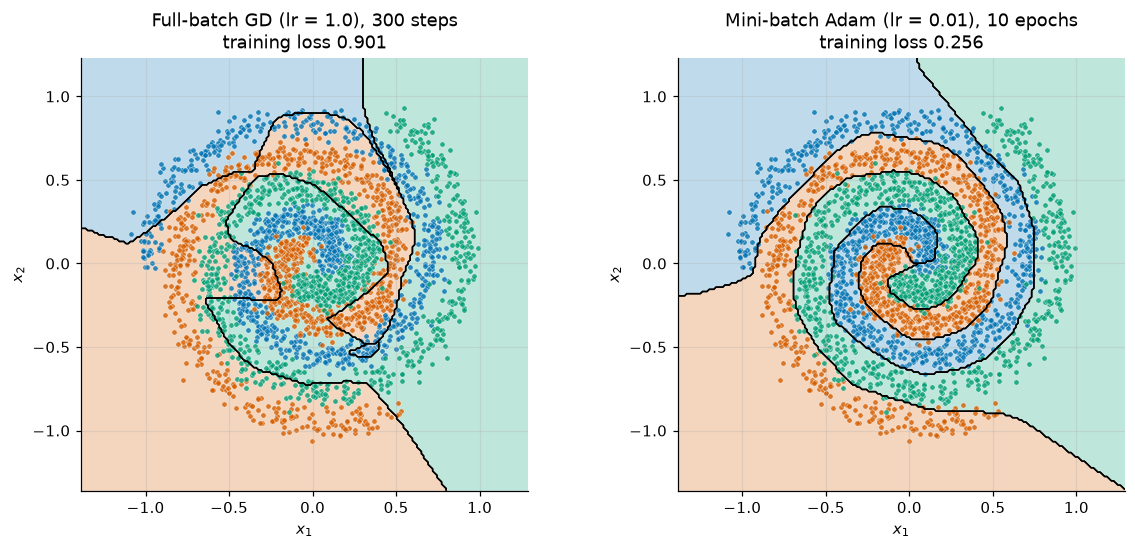

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, model, title in [(axes[0], gd_model, f"Full-batch GD (lr = {gd_lr}), 300 steps"),
                         (axes[1], adam_model, "Mini-batch Adam (lr = 0.01), 10 epochs")]:
    plot_decision_boundary(lambda G, m=model: m(G).argmax(dim=1), X_sp, y_sp, ax=ax,
                           title=f"{title}\ntraining loss {full_loss(model):.3f}")
plt.tight_layout()
plt.show()

Full-batch gradient descent, even at its best learning rate, has barely started: its regions are crude wedges and its loss (0.90) is only a little below the $\ln 3 \approx 1.10$ of random guessing. (The initial loss 1.11 is close to $\ln 3$ because the default initialization gives small, nearly uniform logits — the check of notebook 13; it is not guaranteed for every initialization.) Adam, with a thirtieth of the computation, has carved out most of the spiral arms.

**Two things differ between these runs, and this notebook separates them.** Adam uses *mini-batches* — many cheap, noisy steps instead of a few exact ones (Section 1) — and it uses an *adaptive, momentum-based update rule* (Sections 2–4). We then look at weight decay (Section 5) and at changing the learning rate during training (Section 6), and finish with a fair comparison of optimizers (Section 7). Along the way we implement every optimizer from scratch and check it against `torch.optim` to the last bit.

## 1. Mini-batch stochastic gradient descent

The training loss is an average over examples, $L(\boldsymbol\theta) = \frac1N\sum_{i=1}^N \ell_i(\boldsymbol\theta)$, where $\ell_i$ is the loss on example $i$. Its gradient is the average of the **per-example gradients** $\mathbf g_i = \nabla\ell_i(\boldsymbol\theta)$:

$$\nabla L = \bar{\mathbf g} = \frac1N\sum_{i=1}^N \mathbf g_i.$$

Computing it costs one forward and backward pass over all $N$ examples. **Mini-batch SGD** instead picks a random subset $\mathcal B$ of $B$ examples and uses

$$\mathbf g_{\mathcal B} = \frac1B\sum_{i \in \mathcal B}\mathbf g_i,$$

which costs $B/N$ as much. (In code, `F.cross_entropy(model(X[idx]), y[idx])` is the mean loss over the batch, so its gradient is exactly $\mathbf g_{\mathcal B}$.) Is this cheap estimate any good?

### The mini-batch gradient is unbiased

Let $\mathcal B$ be a uniformly random subset of size $B$, drawn without replacement. Write $\mathbb 1[i \in \mathcal B]$ for the indicator that is 1 when example $i$ is in the batch. Then $\mathbf g_{\mathcal B} = \frac1B\sum_{i=1}^N \mathbb 1[i \in \mathcal B]\,\mathbf g_i$, and by linearity of expectation (notebook 04)

$$\mathbb E[\mathbf g_{\mathcal B}] = \frac1B\sum_{i=1}^N P(i \in \mathcal B)\,\mathbf g_i = \frac1B\sum_{i=1}^N \frac BN\,\mathbf g_i = \bar{\mathbf g},$$

because by symmetry every example has the same chance $B/N$ of being among the $B$ chosen. **On average, the mini-batch gradient is the full gradient.** Each step goes in the right direction *on average*, with some noise around it.

To check this we need every per-example gradient. We compute them with a plain loop — one backward pass per example — at the initial parameters, and store them as the rows of a matrix $G$ of shape `(N, P)`, with $P$ the number of parameters.

In [6]:
probe = make_mlp(0)
params = list(probe.parameters())


def flat_grad(model):
    """Concatenate all parameter gradients into one vector of shape (P,)."""
    return torch.cat([p.grad.reshape(-1) for p in model.parameters()])


G = torch.empty(N, n_params)                              # (N, P) per-example gradients
for i in range(N):
    probe.zero_grad()
    F.cross_entropy(probe(X_sp[i:i + 1]), y_sp[i:i + 1]).backward()
    G[i] = flat_grad(probe)
g_full = G.mean(dim=0)                                    # (P,) the full gradient as an average

probe.zero_grad()
F.cross_entropy(probe(X_sp), y_sp).backward()
print("max |mean of per-example gradients - full-batch autograd gradient| =",
      f"{(g_full - flat_grad(probe)).abs().max().item():.1e}")

idx = torch.tensor([5, 17, 2900, 1234])
probe.zero_grad()
F.cross_entropy(probe(X_sp[idx]), y_sp[idx]).backward()
print("max |G[idx].mean(0) - autograd gradient of the batch loss| =",
      f"{(G[idx].mean(dim=0) - flat_grad(probe)).abs().max().item():.1e}")

max |mean of per-example gradients - full-batch autograd gradient| = 1.1e-07
max |G[idx].mean(0) - autograd gradient of the batch loss| = 1.5e-08


Both agree to `float32` rounding, so from now on a mini-batch gradient is simply `G[idx].mean(0)`, which is far cheaper than a backward pass.

Now average many mini-batch gradients ($B = 32$) and compare with $\bar{\mathbf g}$. An average of $K$ batches is a weighted average of the rows of $G$, weighted by how often each example was drawn, so we only need the counts.

In [7]:
gen = torch.Generator().manual_seed(1)
B = 32
print("  batches K   relative error ||avg of K batch gradients - full|| / ||full||")
for n_batches in [1, 10, 100, 1000, 10000]:
    draws = torch.stack([torch.randperm(N, generator=gen)[:B] for _ in range(n_batches)])   # (K, B) batches
    counts = torch.bincount(draws.reshape(-1), minlength=N).float()                        # (N,) times drawn
    g_avg = counts @ G / (n_batches * B)                                                   # (P,)
    print(f"{n_batches:>10}   {((g_avg - g_full).norm() / g_full.norm()).item():.4f}")
print(f"fraction of batches containing example 0 (last run): {(draws == 0).any(dim=1).float().mean().item():.4f}, "
      f"B/N = {B / N:.4f}")

  batches K   relative error ||avg of K batch gradients - full|| / ||full||
         1   1.7962
        10   0.4698
       100   0.1718
      1000   0.0756


     10000   0.0300
fraction of batches containing example 0 (last run): 0.0100, B/N = 0.0107


The error of the average falls by about $\sqrt{10} \approx 3.2$ for every tenfold increase in $K$ — the $1/\sqrt K$ law for sample averages of notebook 04 — so the mean of the mini-batch gradients converges to the full gradient: no systematic bias. Each example lands in a batch with probability $B/N$, as the proof used.

### The noise shrinks like $1/B$

Unbiased is not the same as accurate: one mini-batch gradient can be far from $\bar{\mathbf g}$. Measure its error by the expected squared distance $\mathbb E\|\mathbf g_{\mathcal B} - \bar{\mathbf g}\|^2$ (the sum of the variances of all $P$ coordinates), and let

$$\sigma^2 = \frac1N\sum_{i=1}^N \|\mathbf g_i - \bar{\mathbf g}\|^2$$

be the spread of the per-example gradients. If the $B$ examples were drawn **with** replacement, they would be independent, each with mean $\bar{\mathbf g}$ and expected squared deviation $\sigma^2$. Expanding $\|\frac1B\sum_k(\mathbf g_{i_k} - \bar{\mathbf g})\|^2$, the cross terms $\mathbb E[(\mathbf g_{i_k} - \bar{\mathbf g})\cdot(\mathbf g_{i_l} - \bar{\mathbf g})]$ vanish for $k \ne l$ by independence, leaving $B$ diagonal terms:

$$\mathbb E\|\mathbf g_{\mathcal B} - \bar{\mathbf g}\|^2 = \frac{1}{B^2}\cdot B\sigma^2 = \frac{\sigma^2}{B}.$$

Drawing **without** replacement (no example twice in a batch) makes the draws slightly negatively correlated and multiplies this by the *finite-population correction* $\frac{N - B}{N - 1}$ (a standard sampling result, stated without proof). It is close to 1 when $B \ll N$ and exactly 0 when $B = N$: the "batch" is then the whole dataset and has no noise.

σ² = 2.4843,   ||full gradient||² = 0.0182
    B   measured E||g_B - g||²   σ²/B·(N-B)/(N-1)
    1              2.446e+00           2.484e+00
    4              6.357e-01           6.204e-01
   16              1.480e-01           1.545e-01
   64              3.886e-02           3.800e-02
  256              9.033e-03           8.879e-03
 1024              1.586e-03           1.598e-03
 3000              1.436e-15           0.000e+00


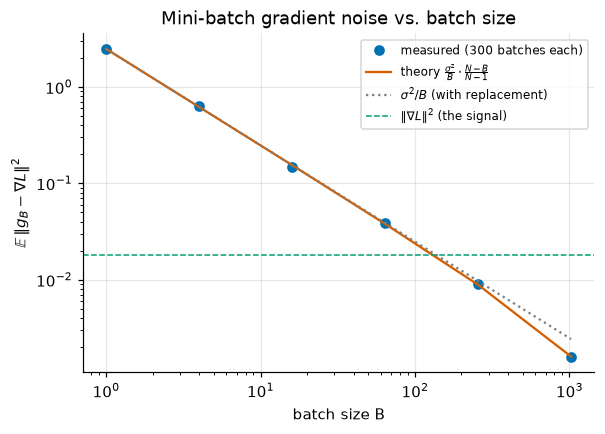

In [8]:
sigma2 = ((G - g_full) ** 2).sum(dim=1).mean().item()
batch_sizes = [1, 4, 16, 64, 256, 1024, 3000]
measured_var, predicted_var = [], []
gen = torch.Generator().manual_seed(2)
for B in batch_sizes:
    errs = torch.stack([((G[torch.randperm(N, generator=gen)[:B]].mean(dim=0) - g_full) ** 2).sum()
                        for _ in range(300)])                                   # 300 random batches
    measured_var.append(errs.mean().item())
    predicted_var.append(sigma2 / B * (N - B) / (N - 1))
print(f"σ² = {sigma2:.4f},   ||full gradient||² = {(g_full ** 2).sum().item():.4f}")
print("    B   measured E||g_B - g||²   σ²/B·(N-B)/(N-1)")
for B, m, p in zip(batch_sizes, measured_var, predicted_var):
    print(f"{B:>5}   {m:20.3e}   {p:17.3e}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(batch_sizes[:-1], measured_var[:-1], "o", color=COLORS[0], label="measured (300 batches each)")
ax.loglog(batch_sizes[:-1], predicted_var[:-1], "-", color=COLORS[1], label="theory $\\frac{\\sigma^2}{B}\\cdot\\frac{N-B}{N-1}$")
ax.loglog(batch_sizes[:-1], [sigma2 / b for b in batch_sizes[:-1]], ":", color="gray", label="$\\sigma^2 / B$ (with replacement)")
ax.axhline((g_full ** 2).sum().item(), color=COLORS[2], ls="--", lw=1, label="$\\|\\nabla L\\|^2$ (the signal)")
ax.set_xlabel("batch size B")
ax.set_ylabel("$\\mathbb{E}\\,\\|g_B - \\nabla L\\|^2$")
ax.set_title("Mini-batch gradient noise vs. batch size")
ax.legend(fontsize=8)
plt.show()

The measured noise follows the theory across three orders of magnitude: a slope of $-1$ on the log–log plot, bending down at the end as $B$ approaches $N$ (and exactly 0 at $B = N = 3000$, printed above). Compare with the green line, the squared length of the true gradient: at this point in training a single example's gradient is mostly noise (in squared length, its deviation is $\sigma^2 / \|\nabla L\|^2 \approx 140$ times larger than the signal), while a batch of 1024 is mostly signal. Note the price: quadrupling $B$ quadruples the cost per step but only **halves** the noise's standard deviation.

### Epochs, steps, and shuffling

An **epoch** is one pass over the training set. With batch size $B$, an epoch is $\lceil N/B \rceil$ **steps** (parameter updates). The standard way to form batches is to draw a fresh random permutation of $0, \dots, N-1$ at the start of every epoch and cut it into consecutive chunks of $B$. Each example is then used exactly once per epoch (sampling without replacement), and the batches differ from epoch to epoch. The last chunk is smaller when $B$ does not divide $N$. Notebook 21 wraps this logic in PyTorch's `DataLoader`; here it is two lines:

In [9]:
def shuffled_batches(n, batch_size, gen):
    """Index tensors for one epoch: a random permutation of range(n) cut into chunks of batch_size."""
    return torch.randperm(n, generator=gen).split(batch_size)


demo = shuffled_batches(10, 4, torch.Generator().manual_seed(0))
print("one epoch, n = 10, B = 4:", [b.tolist() for b in demo])
print("covers every example exactly once:", sorted(torch.cat(demo).tolist()) == list(range(10)))

one epoch, n = 10, B = 4: [[4, 1, 7, 5], [3, 9, 0, 8], [6, 2]]
covers every example exactly once: True


### Checkpoint 1.1

For our $N = 3000$ examples, by hand first:

1. `steps_per_epoch` with $B = 64$, and `last_batch` — the size of the final, smaller batch.
2. `noise_ratio`: by what factor does $\mathbb E\|\mathbf g_{\mathcal B} - \bar{\mathbf g}\|^2$ (without replacement) shrink when $B$ goes from 16 to 64? Use the formula with the finite-population correction.

<details>
<summary><b>💡 Hint</b></summary>

$3000 = 46 \times 64 + 56$. For the ratio, $\sigma^2$ cancels: $\frac{(N - 16)/16}{(N - 64)/64}$.

</details>

In [10]:
steps_per_epoch = math.ceil(3000 / 64)
last_batch = 3000 - (steps_per_epoch - 1) * 64
noise_ratio = ((3000 - 16) / 16) / ((3000 - 64) / 64)
print(steps_per_epoch, last_batch, noise_ratio)

47 56 4.0653950953678475


In [11]:
_b = shuffled_batches(3000, 64, torch.Generator().manual_seed(0))
check(steps_per_epoch == len(_b), f"steps_per_epoch = {steps_per_epoch}, expected {len(_b)}")
check(last_batch == len(_b[-1]), f"last_batch = {last_batch}, expected {len(_b[-1])}")
check_close(noise_ratio, predicted_var[2] / predicted_var[3], "noise_ratio")
passed("Checkpoint 1.1")

✅ Checkpoint 1.1 passed


### Full batch versus mini-batch, at equal cost

A fair comparison of full-batch GD and mini-batch SGD counts **examples processed** — the number of per-example gradients computed, which is what costs time — not steps. One GD step costs 3000; one SGD step with $B = 32$ costs 32. We give both 30 epochs' worth of per-example gradients and, to be generous to GD, let it run ten times longer as well. Each method gets a learning rate that worked well for it (GD's from the motivating problem; for SGD, 0.3 — Section 7 and the exercises tune learning rates properly). We record the full training loss along the way, and the mini-batch losses SGD actually sees.

In [12]:
def run_sgd(lr, batch_size, epochs, seed=0, record_batches=False):
    """Plain mini-batch SGD on the spirals. Returns (examples seen after each epoch, full loss after each epoch,
    per-step batch losses if requested)."""
    model = make_mlp(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)
    seen, losses, batch_losses = [0], [full_loss(model)], []
    for epoch in range(epochs):
        for idx in shuffled_batches(N, batch_size, gen):
            opt.zero_grad()
            loss = F.cross_entropy(model(X_sp[idx]), y_sp[idx])
            loss.backward()
            opt.step()
            if record_batches:
                batch_losses.append(loss.item())
        seen.append(seen[-1] + N)
        losses.append(full_loss(model))
    return seen, losses, batch_losses


t0 = time.perf_counter()
gd_seen, gd_losses, _ = run_sgd(gd_lr, N, epochs=300)          # B = N: full-batch gradient descent
t_gd = time.perf_counter() - t0
t0 = time.perf_counter()
sgd_seen, sgd_losses, sgd_batch_losses = run_sgd(0.3, 32, epochs=30, record_batches=True)
t_sgd = time.perf_counter() - t0
print(f"full-batch GD (lr = {gd_lr}): 300 steps, {gd_seen[-1]:,} examples, final loss {gd_losses[-1]:.4f}, {t_gd:.1f} s")
print(f"   ... after 30 steps ({gd_seen[30]:,} examples): loss {gd_losses[30]:.4f}")
print(f"mini-batch SGD (lr = 0.3, B = 32): {30 * math.ceil(N / 32)} steps, {sgd_seen[-1]:,} examples, "
      f"final loss {sgd_losses[-1]:.4f}, {t_sgd:.1f} s")

full-batch GD (lr = 1.0): 300 steps, 900,000 examples, final loss 0.8953, 0.5 s
   ... after 30 steps (90,000 examples): loss 1.0537
mini-batch SGD (lr = 0.3, B = 32): 2820 steps, 90,000 examples, final loss 0.2433, 0.8 s


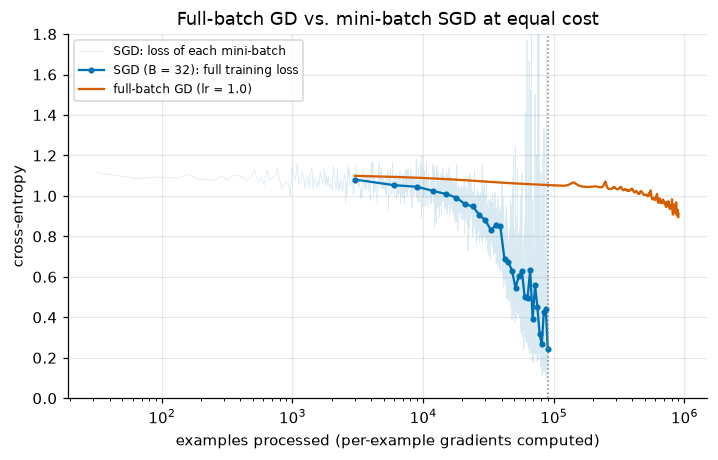

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
steps_x = torch.arange(1, len(sgd_batch_losses) + 1) * 32
ax.semilogx(steps_x, sgd_batch_losses, color=COLORS[0], alpha=0.15, lw=0.5, label="SGD: loss of each mini-batch")
ax.semilogx(sgd_seen[1:], sgd_losses[1:], "o-", color=COLORS[0], ms=3, label="SGD (B = 32): full training loss")
ax.semilogx(gd_seen[1:], gd_losses[1:], "-", color=COLORS[1], label=f"full-batch GD (lr = {gd_lr})")
ax.axvline(30 * N, color="gray", ls=":", lw=1)
ax.set_ylim(0, 1.8)                                    # a few mini-batch losses spike higher; clipped for readability
ax.set_xlabel("examples processed (per-example gradients computed)")
ax.set_ylabel("cross-entropy")
ax.set_title("Full-batch GD vs. mini-batch SGD at equal cost")
ax.legend(fontsize=8)
plt.show()

At the dotted line (30 epochs each), SGD's loss is far below GD's; GD needs the full ten times more computation just to get going, and is still far behind. SGD took about 94 steps per epoch, each nearly as useful as a full-batch step, so it made about 94 times more progress per example. The wall-clock times printed above tell the same story on this CPU, but treat them as indicative only: on a GPU a batch of 3000 costs little more than a batch of 32, which shifts the balance (Chapter 5). The pale trace shows what SGD actually sees: the per-batch losses scatter widely around the full loss (a few spike above the top of the axis, up to about 5).

Mini-batches win when examples are **redundant**: a random batch of 32 spiral points already tells us roughly which way to go, so computing the other 2968 gradients before taking a step is mostly wasted. That is true of nearly every real dataset.

**Noise as a feature (a heuristic, not a theorem).** The gradient noise is often argued to help: a noisy step can carry the parameters out of flat regions and saddle points where the exact gradient is nearly zero, and some work links the noise to finding "flatter" minima that generalize better. These arguments are partly supported by experiments and by analyses of simplified models, but they are not general guarantees, and we do not test them here. What *is* certain is the cost: near a minimum, the noise keeps the parameters jittering, so the learning rate must eventually be reduced to settle (Section 6).

## 2. Momentum

Notebook 03 showed the other weakness of gradient descent: on an **ill-conditioned** bowl $f(\mathbf x) = \frac12(\lambda_1 x_1^2 + \lambda_2 x_2^2)$ with $\lambda = (1, 20)$, the learning rate is limited by the steep direction ($\eta < 2/20$), so the iterate zig-zags across the valley while crawling along it. With $\eta = 0.09$ it needed 73 steps to shrink $\|\mathbf x\|$ by $10^3$.

**Momentum** (the "heavy ball" method, Polyak 1964) keeps a running **velocity** $\mathbf v$ that accumulates gradients:

$$\mathbf v_t = \beta\,\mathbf v_{t-1} + \mathbf g_t, \qquad \boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\mathbf v_t, \qquad \mathbf v_0 = \mathbf 0,$$

with $0 \le \beta < 1$ ($\beta = 0$ is plain gradient descent). Across the valley the gradient flips sign every step, so successive gradients **cancel** in $\mathbf v$; along the valley they point the same way and **add up**. A ball rolling down the valley behaves the same way: its inertia smooths out the side-to-side bouncing and keeps it moving along the floor.

β = 0.0: steps to shrink ||x|| by 1e3: 73
β = 0.5: steps to shrink ||x|| by 1e3: 24


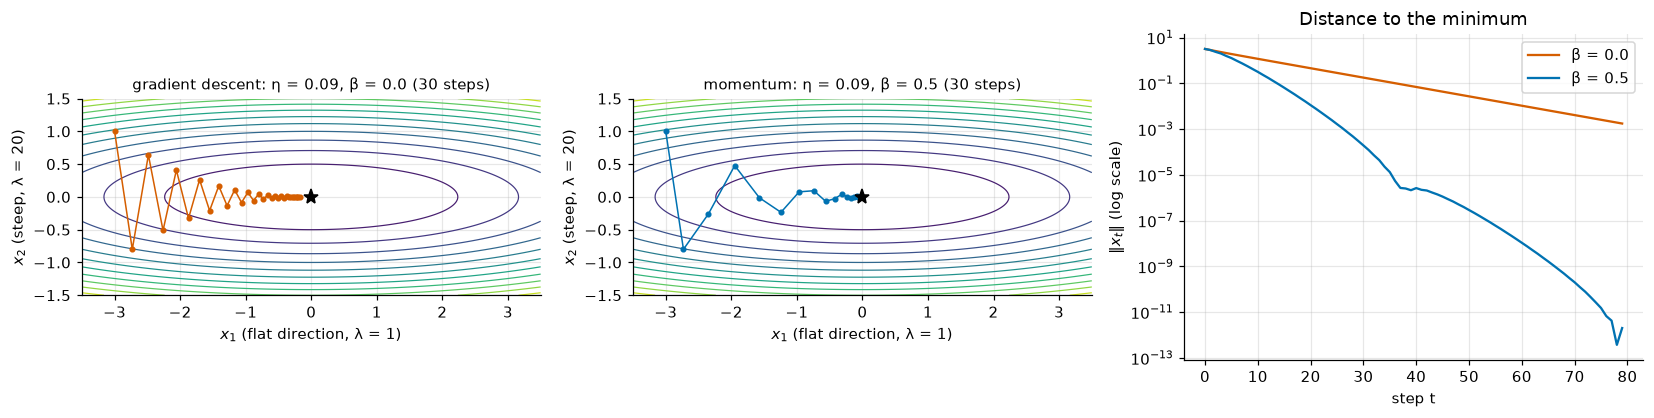

In [14]:
def heavy_ball(lambdas, eta, beta, x0=(-3.0, 1.0), steps=300, tol=1e-3):
    """Momentum on f(x) = ½ Σ λ_i x_i². Returns the path (steps+1, 2) and the first step with ||x|| < tol·||x0||."""
    lam = torch.tensor(lambdas, dtype=f64)
    x = torch.tensor(x0, dtype=f64)
    v = torch.zeros(2, dtype=f64)
    path, reached = [x], None
    for t in range(1, steps + 1):
        v = beta * v + lam * x          # gradient of f is (λ1 x1, λ2 x2)
        x = x - eta * v
        path.append(x)
        if reached is None and x.norm() < tol * path[0].norm():
            reached = t
    return torch.stack(path), reached


lams = (1.0, 20.0)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
g1, g2 = torch.meshgrid(torch.linspace(-3.5, 3.5, 200, dtype=f64), torch.linspace(-1.5, 1.5, 200, dtype=f64), indexing="xy")
for ax, beta, col in [(axes[0], 0.0, COLORS[1]), (axes[1], 0.5, COLORS[0])]:
    path, reached = heavy_ball(lams, 0.09, beta)
    print(f"β = {beta}: steps to shrink ||x|| by 1e3: {reached}")
    ax.contour(g1, g2, 0.5 * (lams[0] * g1**2 + lams[1] * g2**2), levels=12, cmap="viridis", linewidths=0.8)
    ax.plot(path[:31, 0], path[:31, 1], "o-", color=col, ms=3, lw=1)
    ax.plot([0], [0], "k*", ms=10)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$ (flat direction, λ = 1)")
    ax.set_ylabel("$x_2$ (steep, λ = 20)")
    ax.set_title(f"{'gradient descent' if beta == 0 else 'momentum'}: η = 0.09, β = {beta} (30 steps)", fontsize=10)
    axes[2].semilogy(path.norm(dim=1)[:80], color=col, label=f"β = {beta}")
axes[2].set_xlabel("step t")
axes[2].set_ylabel("$\\|x_t\\|$ (log scale)")
axes[2].set_title("Distance to the minimum")
axes[2].legend()
plt.tight_layout()
plt.show()

With the same learning rate, momentum $\beta = 0.5$ makes visibly larger strides along the flat $x_1$ direction, and its oscillation across the valley dies out instead of persisting. It reaches the tolerance in 24 steps instead of 73.

**Why, exactly.** As in notebook 03, each coordinate evolves on its own. For one coordinate with curvature $\lambda$, the pair $(x, v)$ is updated by a linear map: $v_t = \beta v_{t-1} + \lambda x_{t-1}$ and $x_t = x_{t-1} - \eta v_t = (1 - \eta\lambda)x_{t-1} - \eta\beta\, v_{t-1}$, that is

$$\begin{pmatrix} x_t \\ v_t\end{pmatrix} = \underbrace{\begin{pmatrix} 1 - \eta\lambda & -\eta\beta \\ \lambda & \beta\end{pmatrix}}_{M}\begin{pmatrix} x_{t-1} \\ v_{t-1}\end{pmatrix}.$$

After $t$ steps the state is $M^t$ times the start, so it shrinks like $\rho^t$, where $\rho$ is the largest absolute eigenvalue of $M$ (the **spectral radius**; stated without proof, it is the 2×2 analogue of the factor $1 - \eta\lambda$). The trace of $M$ is $1 + \beta - \eta\lambda$ and its determinant is $\beta(1 - \eta\lambda) + \eta\beta\lambda = \beta$. So the eigenvalues solve $\mu^2 - (1 + \beta - \eta\lambda)\mu + \beta = 0$; when they are complex (the iterate spirals in), both have $|\mu| = \sqrt{\beta}$, since their product is $\beta$.

In [15]:
def heavy_ball_rate(lam, eta, beta):
    """Spectral radius of the momentum iteration matrix for one direction with curvature lam."""
    M = torch.tensor([[1 - eta * lam, -eta * beta], [lam, beta]], dtype=f64)
    return torch.linalg.eigvals(M).abs().max().item()


for beta in [0.0, 0.5]:
    rates = [heavy_ball_rate(lam, 0.09, beta) for lam in lams]
    rho = max(rates)
    print(f"β = {beta}: rate per direction (λ=1, λ=20) = ({rates[0]:.4f}, {rates[1]:.4f}); "
          f"predicted steps ≈ ln(1e-3)/ln ρ = {math.log(1e-3) / math.log(rho):.1f}")

β = 0.0: rate per direction (λ=1, λ=20) = (0.9100, 0.8000); predicted steps ≈ ln(1e-3)/ln ρ = 73.2
β = 0.5: rate per direction (λ=1, λ=20) = (0.7071, 0.7071); predicted steps ≈ ln(1e-3)/ln ρ = 19.9


For $\beta = 0$ the rates are $|1 - \eta\lambda|$: $0.91$ along the flat direction is the bottleneck. With $\beta = 0.5$ both directions have complex eigenvalues of modulus $\sqrt{0.5} \approx 0.707$, and $\ln(10^{-3})/\ln 0.707 \approx 20$ steps — the measured 24 includes the transient before the asymptotic rate takes over.

**How much can momentum gain?** With the best learning rate, gradient descent needs a number of steps proportional to $\kappa = \lambda_{\max}/\lambda_{\min}$ (notebook 03, Exercise 4). For heavy ball on quadratics, the best choice is $\eta = 4/(\sqrt{\lambda_{\max}} + \sqrt{\lambda_{\min}})^2$ and $\beta = \big(\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}\big)^2$, giving the rate $\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}$ (Polyak 1964; stated without proof). Steps then grow like $\sqrt\kappa$ instead of $\kappa$:

In [16]:
print("    κ   best GD steps   best momentum steps   (to shrink ||x|| by 1e6)")
for kappa in [10, 100, 1000]:
    _, gd_steps = heavy_ball((1.0, kappa), 2 / (1 + kappa), 0.0, steps=20000, tol=1e-6)
    eta_hb = 4 / (math.sqrt(kappa) + 1) ** 2
    beta_hb = ((math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1)) ** 2
    _, hb_steps = heavy_ball((1.0, kappa), eta_hb, beta_hb, steps=20000, tol=1e-6)
    print(f"{kappa:>5}   {gd_steps:>13}   {hb_steps:>19}")

    κ   best GD steps   best momentum steps   (to shrink ||x|| by 1e6)
   10              69                    26


  100             691                    89


 1000            6908                   301


A hundredfold increase in $\kappa$ costs gradient descent about 100 times more steps, and momentum about 10 times more. For $\kappa = 1000$ that is 6,908 steps against a few hundred. (A real network's loss is not a quadratic, and we never know its curvatures, so these optimal settings are not usable directly; but the mechanism — cancel the oscillating components, accumulate the consistent ones — carries over. In practice $\beta = 0.9$ is the usual default.)

### Momentum as an exponential moving average

Unrolling the recursion from $\mathbf v_0 = \mathbf 0$:

$$\mathbf v_t = \mathbf g_t + \beta\mathbf g_{t-1} + \beta^2\mathbf g_{t-2} + \dots + \beta^{t-1}\mathbf g_1 = \sum_{k=0}^{t-1}\beta^k\,\mathbf g_{t-k}.$$

The velocity is a weighted sum of all past gradients, with weights decaying geometrically into the past. Two consequences:

- **Effective learning rate.** If the gradient is constant, $\mathbf g_t = \mathbf g$, then $\mathbf v_t = \mathbf g(1 + \beta + \dots + \beta^{t-1}) = \mathbf g\,\frac{1 - \beta^t}{1 - \beta} \to \frac{\mathbf g}{1 - \beta}$. Along a consistent slope the step is $\frac{\eta}{1-\beta}$ times the gradient: **ten times** larger for $\beta = 0.9$.
- **Memory.** A gradient from $k$ steps ago has weight $\beta^k$. Since $\beta^{1/(1-\beta)} \approx e^{-1}$ for $\beta$ near 1 (because $\ln\beta \approx -(1 - \beta)$), the velocity effectively averages over the last $\frac{1}{1-\beta}$ steps: about 10 steps for $\beta = 0.9$, 100 for $\beta = 0.99$.

In [17]:
beta, g_const = 0.9, 2.0
v = 0.0
for t in range(1, 51):
    v = beta * v + g_const
    if t in (1, 2, 10, 50):
        print(f"t = {t:>2}: v = {v:.4f},  formula g(1-β^t)/(1-β) = {g_const * (1 - beta**t) / (1 - beta):.4f}")
print(f"limit g/(1-β) = {g_const / (1 - beta):.1f};   β^(1/(1-β)) = {beta ** (1 / (1 - beta)):.3f} vs e^-1 = {math.exp(-1):.3f}")

t =  1: v = 2.0000,  formula g(1-β^t)/(1-β) = 2.0000
t =  2: v = 3.8000,  formula g(1-β^t)/(1-β) = 3.8000
t = 10: v = 13.0264,  formula g(1-β^t)/(1-β) = 13.0264
t = 50: v = 19.8969,  formula g(1-β^t)/(1-β) = 19.8969
limit g/(1-β) = 20.0;   β^(1/(1-β)) = 0.349 vs e^-1 = 0.368


**Conventions differ.** Some texts write the velocity as an *average*, $\mathbf v_t = \beta\mathbf v_{t-1} + (1 - \beta)\mathbf g_t$, which removes the factor $\frac{1}{1-\beta}$ (so a good $\eta$ is ten times larger); others fold the learning rate into the velocity, $\mathbf v_t = \beta\mathbf v_{t-1} - \eta\mathbf g_t$, $\boldsymbol\theta_t = \boldsymbol\theta_{t-1} + \mathbf v_t$ (as in Sutskever et al. 2013). For a constant learning rate all three produce the same iterates after rescaling $\eta$; they differ when $\eta$ changes during training, because in the last form old gradients keep the old learning rate.

PyTorch's `torch.optim.SGD(params, lr, momentum, dampening=0)` uses our form. Per its documentation, for each parameter tensor:

$$\mathbf b_t = \begin{cases}\mathbf g_1 & t = 1\\ \mu\,\mathbf b_{t-1} + (1 - \text{dampening})\,\mathbf g_t & t > 1\end{cases}, \qquad \boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \text{lr}\cdot\mathbf b_t,$$

where the buffer $\mathbf b$ is our $\mathbf v$ and $\mu$ is our $\beta$. The learning rate multiplies the whole buffer at every step, and with the default `dampening=0` the first step's special case agrees with $\mathbf v_0 = \mathbf 0$.

### Implementing momentum and matching `torch.optim.SGD`

An optimizer is just a function that updates parameters in place from their `.grad`, inside `torch.no_grad()` (notebook 05), and keeps some **state** — here one velocity tensor per parameter. To test our implementations we use one harness for the whole notebook: two copies of the same MLP, fed identical mini-batches, one updated by a `torch.optim` optimizer and one by our function, comparing their parameters after every step.

In [18]:
def lockstep(make_torch_opt, my_step, steps, seed=0, batch_size=64):
    """Train two identical MLPs on identical mini-batches: one with make_torch_opt(params), one with
    my_step(params, state). Returns the max |parameter difference| after each step."""
    model_ref, model_mine = make_mlp(seed), make_mlp(seed)
    opt = make_torch_opt(model_ref.parameters())
    params_mine = list(model_mine.parameters())
    state = {}
    gen = torch.Generator().manual_seed(seed)
    diffs = []
    for _ in range(steps):
        idx = torch.randint(0, N, (batch_size,), generator=gen)   # random batch (with replacement, for simplicity)
        for model in (model_ref, model_mine):
            model.zero_grad()
            F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
        opt.step()
        my_step(params_mine, state)
        diffs.append(max((a - b).abs().max().item() for a, b in zip(model_ref.parameters(), params_mine)))
    return diffs


def sgd_momentum_step(params, state, lr, beta):
    """One heavy-ball step: v <- beta v + g; theta <- theta - lr v. state holds one velocity per parameter."""
    with torch.no_grad():
        for i, p in enumerate(params):
            if i not in state:
                state[i] = torch.zeros_like(p)        # v_0 = 0
            v = state[i]
            v.mul_(beta).add_(p.grad)                 # v <- beta v + g     (in place)
            p.add_(v, alpha=-lr)                      # theta <- theta - lr v


diffs = lockstep(lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9),
                 lambda ps, st: sgd_momentum_step(ps, st, lr=0.1, beta=0.9), steps=50)
print("max |difference| after steps 1, 10, 50:", diffs[0], diffs[9], diffs[49])
check(max(diffs) == 0.0, "momentum should match torch.optim.SGD exactly")
passed("sgd_momentum_step matches torch.optim.SGD(momentum=0.9) bit for bit over 50 steps")

max |difference| after steps 1, 10, 50: 0.0 0.0 0.0
✅ sgd_momentum_step matches torch.optim.SGD(momentum=0.9) bit for bit over 50 steps passed


The parameters agree **exactly** — zero difference, not just a small one — after 50 steps. That required performing the same floating-point operations in the same order as PyTorch. A mathematically identical variant, `p.sub_(lr * v)`, rounds `lr * v` to `float32` before subtracting, while `p.add_(v, alpha=-lr)` computes $p - \text{lr}\cdot v$ in one operation:

In [19]:
def sgd_momentum_step_v2(params, state, lr, beta):
    with torch.no_grad():
        for i, p in enumerate(params):
            v = state.setdefault(i, torch.zeros_like(p))
            v.mul_(beta).add_(p.grad)
            p.sub_(lr * v)                            # rounds lr * v first


diffs_v2 = lockstep(lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9),
                    lambda ps, st: sgd_momentum_step_v2(ps, st, lr=0.1, beta=0.9), steps=50)
print(f"max |difference| after 50 steps with p.sub_(lr * v): {max(diffs_v2):.1e}")

max |difference| after 50 steps with p.sub_(lr * v): 7.5e-08


The difference is at the level of `float32` rounding ($\sim 10^{-7}$), so both are correct implementations of the algorithm. We insist on bitwise equality only because it makes the test unambiguous; Section 4 shows why "close" can be hard to judge for adaptive optimizers.

**Nesterov momentum** (`nesterov=True`) is a variant that evaluates the momentum step "one step ahead"; PyTorch implements it as $\boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \text{lr}\,(\mathbf g_t + \mu\,\mathbf b_t)$. Exercise 2 implements it together with the other options of `torch.optim.SGD`.

### Checkpoint 2.1

A single parameter starts at $\theta_0 = 0$ and its gradient is the constant $g = 2$. Using momentum with $\eta = 0.1$ and $\beta = 0.9$, compute by hand: `v3`, the velocity after 3 steps; `theta3`, the parameter after 3 steps; and `v_limit`, the velocity as $t \to \infty$.

<details>
<summary><b>💡 Hint</b></summary>

$v_1 = 2$, $v_2 = 0.9 \cdot 2 + 2 = 3.8$, $v_3 = 0.9 \cdot 3.8 + 2$. The parameter moves by $-\eta v_t$ at each step, so $\theta_3 = -0.1(v_1 + v_2 + v_3)$. The limit is $g/(1 - \beta)$.

</details>

In [20]:
v3 = 2 * (1 + 0.9 + 0.81)
theta3 = -0.1 * (2 + 3.8 + v3)
v_limit = 2 / (1 - 0.9)
print(v3, theta3, v_limit)

5.42 -1.1219999999999999 20.000000000000004


In [21]:
_p = torch.zeros(1, requires_grad=True)
_opt = torch.optim.SGD([_p], lr=0.1, momentum=0.9)
for _ in range(3):
    _p.grad = torch.full((1,), 2.0)
    _opt.step()
check_close(v3, _opt.state[_p]["momentum_buffer"].item(), "v3")
check_close(theta3, _p.item(), "theta3")
check_close(v_limit, 20.0, "v_limit")
passed("Checkpoint 2.1")

✅ Checkpoint 2.1 passed


## 3. RMSProp: a step size per parameter

Momentum still uses **one** learning rate for every parameter. But in a network, different parameters can have gradients of very different sizes — the weights of different layers, or a bias versus a weight. With one $\eta$, the parameter with the largest gradients (more precisely, the largest curvature) dictates a small learning rate for all.

**RMSProp** (Tieleman and Hinton 2012, introduced in a lecture of Hinton's Coursera course rather than a paper) divides each coordinate's gradient by a running estimate of that coordinate's typical gradient size, the root mean square:

$$\mathbf s_t = \alpha\,\mathbf s_{t-1} + (1 - \alpha)\,\mathbf g_t^2, \qquad \boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\frac{\mathbf g_t}{\sqrt{\mathbf s_t} + \varepsilon}, \qquad \mathbf s_0 = \mathbf 0.$$

Squares, square roots and the division are **elementwise**. $\mathbf s_t$ is an exponential moving average of squared gradients (the same averaging as momentum, but normalized by $1 - \alpha$, so it is a weighted mean rather than a sum), and $\varepsilon$ (default $10^{-8}$) only prevents division by zero. If a coordinate's gradients are typically of size $c$, then $\sqrt{s} \approx c$ and the step is about $\eta \cdot g/c$: **unit-free**. Rescaling one parameter's gradients by 100 leaves its steps unchanged.

We test this on a bowl whose two axes have very different curvatures, $\lambda = (1, 100)$, so the gradients $\lambda_i x_i$ differ in scale by up to 100. Gradient descent needs $\eta < 2/100$; we give it $\eta = 0.019$.

GD, η = 0.019     : ||x|| after 10, 50, 200 steps = 2.50e+00, 1.15e+00, 6.47e-02
RMSProp, η = 0.03 : ||x|| after 10, 50, 200 steps = 1.65e+00, 3.44e-01, 4.21e-05
RMSProp, η = 0.1  : ||x|| after 10, 50, 200 steps = 1.47e-01, 3.85e-07, 1.81e-47


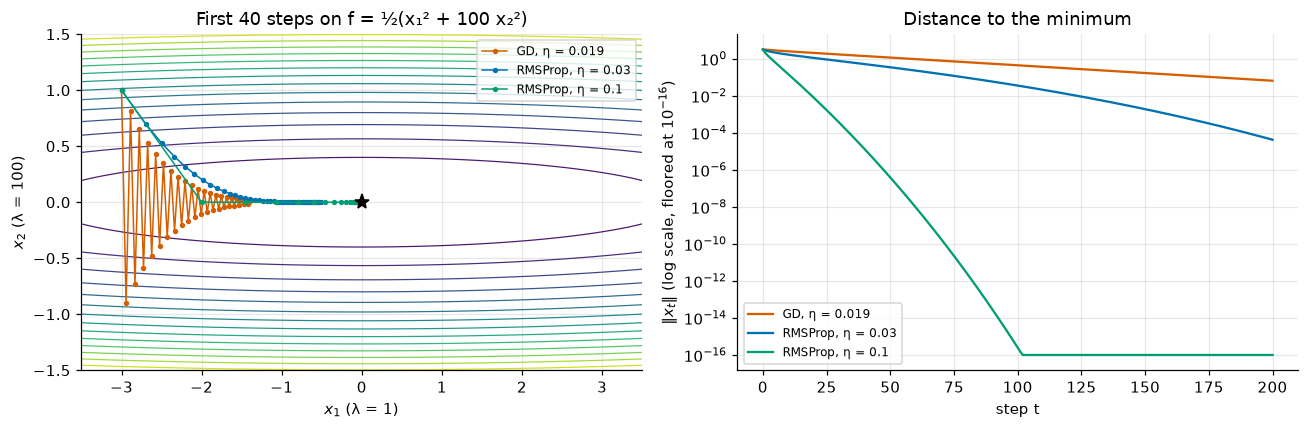

In [22]:
def run_rmsprop_quadratic(A, lr, alpha=0.99, eps=1e-8, x0=(-3.0, 1.0), steps=200):
    """RMSProp on f(x) = ½ xᵀ A x (gradient A x). Returns the path (steps+1, 2)."""
    x = torch.tensor(x0, dtype=f64)
    s = torch.zeros(2, dtype=f64)
    path = [x]
    for _ in range(steps):
        g = A @ x
        s = alpha * s + (1 - alpha) * g**2
        x = x - lr * g / (s.sqrt() + eps)
        path.append(x)
    return torch.stack(path)


def run_gd_quadratic(A, lr, x0=(-3.0, 1.0), steps=200):
    x = torch.tensor(x0, dtype=f64)
    path = [x]
    for _ in range(steps):
        x = x - lr * (A @ x)
        path.append(x)
    return torch.stack(path)


A_axis = torch.diag(torch.tensor([1.0, 100.0], dtype=f64))
c45 = math.cos(math.pi / 4)
R45 = torch.tensor([[c45, -c45], [c45, c45]], dtype=f64)
A_rot = R45 @ A_axis @ R45.T                       # same curvatures, axes rotated by 45°

runs = {"GD, η = 0.019": run_gd_quadratic(A_axis, 0.019),
        "RMSProp, η = 0.03": run_rmsprop_quadratic(A_axis, 0.03),
        "RMSProp, η = 0.1": run_rmsprop_quadratic(A_axis, 0.1)}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
h1, h2 = torch.meshgrid(torch.linspace(-3.5, 3.5, 200, dtype=f64), torch.linspace(-1.5, 1.5, 200, dtype=f64), indexing="xy")
ax1.contour(h1, h2, 0.5 * (h1**2 + 100 * h2**2), levels=14, cmap="viridis", linewidths=0.8)
for k, (name, path) in enumerate(runs.items()):
    ax1.plot(path[:41, 0], path[:41, 1], "o-", ms=2.5, lw=1, color=COLORS[[1, 0, 2][k]], label=name)
    ax2.semilogy(path.norm(dim=1).clamp_min(1e-16), color=COLORS[[1, 0, 2][k]], label=name)
    print(f"{name:18s}: ||x|| after 10, 50, 200 steps = {path[10].norm().item():.2e}, "
          f"{path[50].norm().item():.2e}, {path[200].norm().item():.2e}")
ax1.plot([0], [0], "k*", ms=10)
ax1.set_xlabel("$x_1$ (λ = 1)")
ax1.set_ylabel("$x_2$ (λ = 100)")
ax1.set_title("First 40 steps on f = ½(x₁² + 100 x₂²)")
ax1.legend(fontsize=8)
ax2.set_xlabel("step t")
ax2.set_ylabel("$\\|x_t\\|$ (log scale, floored at $10^{-16}$)")
ax2.set_title("Distance to the minimum")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Gradient descent zig-zags across the steep $x_2$ direction (factor $1 - 0.019 \cdot 100 = -0.9$ per step) while crawling along $x_1$ (factor $0.981$). RMSProp moves **both coordinates at similar speed** — its first steps head diagonally, about the same distance in $x_1$ and $x_2$ (the very first is $10\eta$ in each coordinate, for a reason explained below) — and with $\eta = 0.1$ it is within $10^{-6}$ of the minimum after 50 steps, when GD is still at distance 1.15. Each coordinate got its own effective learning rate $\eta/\sqrt{s_i}$, small for the steep coordinate and large for the flat one.

**A limitation.** RMSProp rescales the *coordinate axes*. If the narrow valley is not aligned with them, it cannot help. The same bowl rotated by 45°:

In [23]:
for name, path in [("GD, η = 0.019", run_gd_quadratic(A_rot, 0.019)),
                   ("RMSProp, η = 0.03", run_rmsprop_quadratic(A_rot, 0.03)),
                   ("RMSProp, η = 0.1", run_rmsprop_quadratic(A_rot, 0.1))]:
    print(f"rotated bowl, {name:18s}: ||x|| after 10, 50, 200 steps = {path[10].norm().item():.2e}, "
          f"{path[50].norm().item():.2e}, {path[200].norm().item():.2e}")

rotated bowl, GD, η = 0.019     : ||x|| after 10, 50, 200 steps = 1.53e+00, 5.42e-01, 3.05e-02
rotated bowl, RMSProp, η = 0.03 : ||x|| after 10, 50, 200 steps = 1.77e+00, 1.38e+00, 1.15e+00
rotated bowl, RMSProp, η = 0.1  : ||x|| after 10, 50, 200 steps = 1.37e+00, 1.12e+00, 3.27e-01


Now both coordinates mix steep and flat directions, have gradients of similar size, and get similar scaling: RMSProp gains nothing and is in fact slower than GD here. Per-parameter scaling is a **diagonal** correction of curvature. Newton's method (chapter 2 problem set) corrects with the full Hessian, which handles rotation but costs far too much for networks. That different parameters of a network often *do* have systematically different gradient scales is why the diagonal correction is useful in practice.

### Implementing RMSProp and matching `torch.optim.RMSprop`

PyTorch's `torch.optim.RMSprop(params, lr=0.01, alpha=0.99, eps=1e-08)` implements the update above. Two details to watch:

- **Naming.** The decay rate of the squared-gradient average is called `alpha` (default 0.99). Other sources call it $\rho$, $\gamma$ or $\beta_2$; Hinton's lecture used 0.9.
- **$\varepsilon$ placement.** PyTorch adds $\varepsilon$ *outside* the square root, $\sqrt{s} + \varepsilon$, as we wrote. Some libraries use $\sqrt{s + \varepsilon}$ — a different algorithm whenever $s$ is not much larger than $\varepsilon$ (with $\varepsilon = 10^{-8}$, $\sqrt\varepsilon = 10^{-4}$ acts as a floor on the denominator).

In [24]:
def rmsprop_step(params, state, lr=0.01, alpha=0.99, eps=1e-8):
    """One RMSProp step: s <- alpha s + (1 - alpha) g²; theta <- theta - lr g / (sqrt(s) + eps)."""
    with torch.no_grad():
        for i, p in enumerate(params):
            if i not in state:
                state[i] = torch.zeros_like(p)                   # s_0 = 0
            s, g = state[i], p.grad
            s.mul_(alpha).addcmul_(g, g, value=1 - alpha)        # s <- alpha s + (1 - alpha) g·g
            p.addcdiv_(g, s.sqrt().add_(eps), value=-lr)         # theta <- theta - lr g / (sqrt(s) + eps)


diffs = lockstep(lambda ps: torch.optim.RMSprop(ps, lr=1e-3),
                 lambda ps, st: rmsprop_step(ps, st, lr=1e-3), steps=100)
print("max |difference| over 100 steps:", max(diffs))
check(max(diffs) == 0.0, "RMSProp should match torch.optim.RMSprop exactly")
passed("rmsprop_step matches torch.optim.RMSprop bit for bit over 100 steps")

max |difference| over 100 steps: 0.0
✅ rmsprop_step matches torch.optim.RMSprop bit for bit over 100 steps passed


(`addcmul_(a, b, value=c)` adds $c\cdot a\cdot b$ and `addcdiv_(a, b, value=c)` adds $c \cdot a / b$, elementwise, in place.)

**The first step is too big.** Since $\mathbf s_0 = \mathbf 0$, after one step $\mathbf s_1 = (1 - \alpha)\mathbf g_1^2$, so $\sqrt{\mathbf s_1} = \sqrt{1 - \alpha}\,|\mathbf g_1|$ and the first update is

$$-\eta\,\frac{\mathbf g_1}{\sqrt{1-\alpha}\,|\mathbf g_1|} = -\frac{\eta}{\sqrt{1 - \alpha}}\operatorname{sign}(\mathbf g_1) = -10\,\eta\,\operatorname{sign}(\mathbf g_1) \quad (\alpha = 0.99),$$

ignoring $\varepsilon$: every parameter moves by ten times the learning rate, whatever its gradient. The estimate $\mathbf s_t$ is biased toward its zero starting value for the first $\sim 1/(1-\alpha) = 100$ steps. Adam fixes exactly this.

In [25]:
p_demo = torch.tensor([0.0, 0.0, 0.0], requires_grad=True)
opt_demo = torch.optim.RMSprop([p_demo], lr=0.01)
p_demo.grad = torch.tensor([0.5, -3.0, 1e-3])
opt_demo.step()
print("gradients            :", p_demo.grad.tolist())
print("first RMSProp update :", p_demo.detach().tolist(), " (lr = 0.01)")

gradients            : [0.5, -3.0, 0.0010000000474974513]
first RMSProp update : [-0.09999997168779373, 0.10000000149011612, -0.09999000281095505]  (lr = 0.01)


### Checkpoint 3.1

One parameter has gradient $g = 0.2$ at the first step and $g = 0.2$ again at the second. With `torch.optim.RMSprop` defaults except `lr=0.001` ($\alpha = 0.99$, $\varepsilon = 10^{-8}$), compute by hand the two updates `update1` and `update2` (the change in the parameter at each step, negative here). Ignore $\varepsilon$ in your hand calculation; the check allows for it.

<details>
<summary><b>💡 Hint</b></summary>

$s_1 = 0.01 \cdot 0.04$, so $\sqrt{s_1} = 0.1 \cdot 0.2$ and the first update is $-0.001 \cdot 0.2 / 0.02$. Then $s_2 = 0.99 \cdot 0.0004 + 0.01 \cdot 0.04 = 0.000796$; use $\sqrt{s_2}$.

</details>

In [26]:
s1 = 0.01 * 0.2**2
update1 = -0.001 * 0.2 / math.sqrt(s1)
s2 = 0.99 * s1 + 0.01 * 0.2**2
update2 = -0.001 * 0.2 / math.sqrt(s2)
print(update1, update2)

-0.01 -0.007088812050083359


In [27]:
_p = torch.zeros(1, requires_grad=True)
_opt = torch.optim.RMSprop([_p], lr=0.001)
_traj = []
for _ in range(2):
    _p.grad = torch.full((1,), 0.2)
    _before = _p.item()
    _opt.step()
    _traj.append(_p.item() - _before)
check_close(update1, _traj[0], "update1", rtol=1e-4)
check_close(update2, _traj[1], "update2", rtol=1e-4)
passed("Checkpoint 3.1")

✅ Checkpoint 3.1 passed


Two identical gradients, yet the second step is about $\sqrt{2}$ times smaller than the first: only the growing $s_t$ changed. Steps keep shrinking toward $\eta$ as $s_t$ approaches $g^2$.

## 4. Adam

**Adam** (Kingma and Ba 2015, "Adam: A Method for Stochastic Optimization", ICLR) combines the two ideas — a moving average of gradients for momentum, and a moving average of squared gradients for per-parameter scaling — and removes the start-up bias of both. For each parameter, at step $t = 1, 2, \dots$, with $\mathbf m_0 = \mathbf v_0 = \mathbf 0$:

$$\begin{aligned}
\mathbf m_t &= \beta_1\mathbf m_{t-1} + (1 - \beta_1)\,\mathbf g_t &&\text{(first moment: average gradient)}\\
\mathbf v_t &= \beta_2\mathbf v_{t-1} + (1 - \beta_2)\,\mathbf g_t^2 &&\text{(second moment: average squared gradient)}\\
\hat{\mathbf m}_t &= \frac{\mathbf m_t}{1 - \beta_1^t}, \qquad \hat{\mathbf v}_t = \frac{\mathbf v_t}{1 - \beta_2^t} &&\text{(bias correction)}\\
\boldsymbol\theta_t &= \boldsymbol\theta_{t-1} - \eta\,\frac{\hat{\mathbf m}_t}{\sqrt{\hat{\mathbf v}_t} + \varepsilon}.
\end{aligned}$$

The defaults, from the paper and in PyTorch, are $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$; PyTorch's default learning rate is $\eta = 10^{-3}$. Note that $\mathbf m$ uses the *averaging* convention (factor $1 - \beta_1$), unlike PyTorch's SGD momentum: Adam's step is in units of $\eta$, without the factor $\frac{1}{1-\beta_1}$.

### Where the bias correction comes from

Unroll $\mathbf m_t$ as we did for momentum:

$$\mathbf m_t = (1 - \beta_1)\sum_{k=1}^{t}\beta_1^{t-k}\,\mathbf g_k.$$

Suppose the gradients have a constant expectation, $\mathbb E[\mathbf g_k] = \mathbf g$ (exactly true if the gradient itself is constant). Then

$$\mathbb E[\mathbf m_t] = (1 - \beta_1)\,\mathbf g\sum_{k=1}^{t}\beta_1^{t-k} = (1 - \beta_1)\,\mathbf g\,\frac{1 - \beta_1^t}{1 - \beta_1} = (1 - \beta_1^t)\,\mathbf g.$$

The weights only sum to $1 - \beta_1^t$ because the average was started at 0, so $\mathbf m_t$ underestimates the gradient early on — at $t = 1$, $\mathbf m_1 = 0.1\,\mathbf g_1$. Dividing by $1 - \beta_1^t$ makes the estimate unbiased; the same argument with $\mathbf g_k^2$ gives $\mathbb E[\mathbf v_t] = (1 - \beta_2^t)\,\mathbb E[\mathbf g^2]$. (Kingma and Ba give this derivation; if the expectations drift slowly, the correction is approximately right.)

**What happens without it?** For a constant gradient, the uncorrected ratio $\mathbf m_t/\sqrt{\mathbf v_t}$ equals the corrected one times

$$r_t = \frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t}}.$$

r_1 = 3.162,  max r_t = 6.569 at t = 12,  r_1000 = 1.258,  r_5000 = 1.003


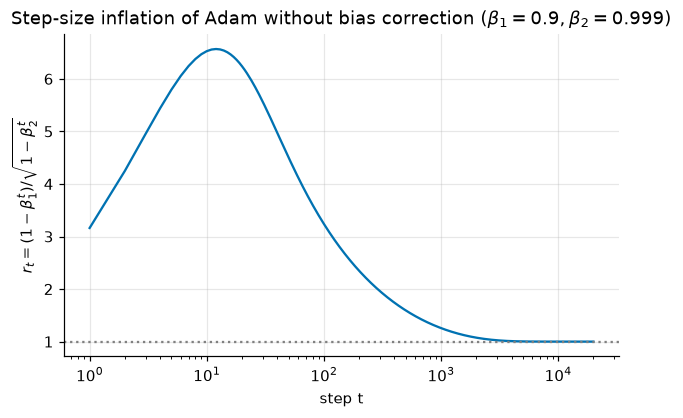

In [28]:
ts = torch.arange(1, 20001, dtype=f64)
r = (1 - 0.9**ts) / torch.sqrt(1 - 0.999**ts)
print(f"r_1 = {r[0].item():.3f},  max r_t = {r.max().item():.3f} at t = {int(ts[r.argmax()].item())},  "
      f"r_1000 = {r[999].item():.3f},  r_5000 = {r[4999].item():.3f}")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(ts, r, color=COLORS[0])
ax.axhline(1, color="gray", ls=":")
ax.set_xlabel("step t")
ax.set_ylabel("$r_t = (1-\\beta_1^t)/\\sqrt{1-\\beta_2^t}$")
ax.set_title("Step-size inflation of Adam without bias correction ($\\beta_1 = 0.9, \\beta_2 = 0.999$)")
plt.show()

Without the correction, the second-moment estimate (slow, $\beta_2 = 0.999$) is far more biased toward zero than the first ($\beta_1 = 0.9$) for the first thousand or so steps, so the steps are **too large**: about 3.2 times at $t = 1$, rising to about 6.6 times at $t = 12$, and still inflated by about 26% after a thousand steps. The early phase is exactly when the parameters are furthest from any sensible solution. Here is what that does to training at three learning rates:

lr = 0.001, corrected  : loss after steps 1, 10, 100 = 1.109, 1.093, 1.046
lr = 0.001, uncorrected: loss after steps 1, 10, 100 = 1.104, 1.065, 0.989
lr = 0.01, corrected  : loss after steps 1, 10, 100 = 1.101, 1.060, 0.948


lr = 0.01, uncorrected: loss after steps 1, 10, 100 = 1.144, 1.078, 0.797
lr = 0.03, corrected  : loss after steps 1, 10, 100 = 1.139, 1.066, 0.870


lr = 0.03, uncorrected: loss after steps 1, 10, 100 = 1.728, 1.072, 0.911


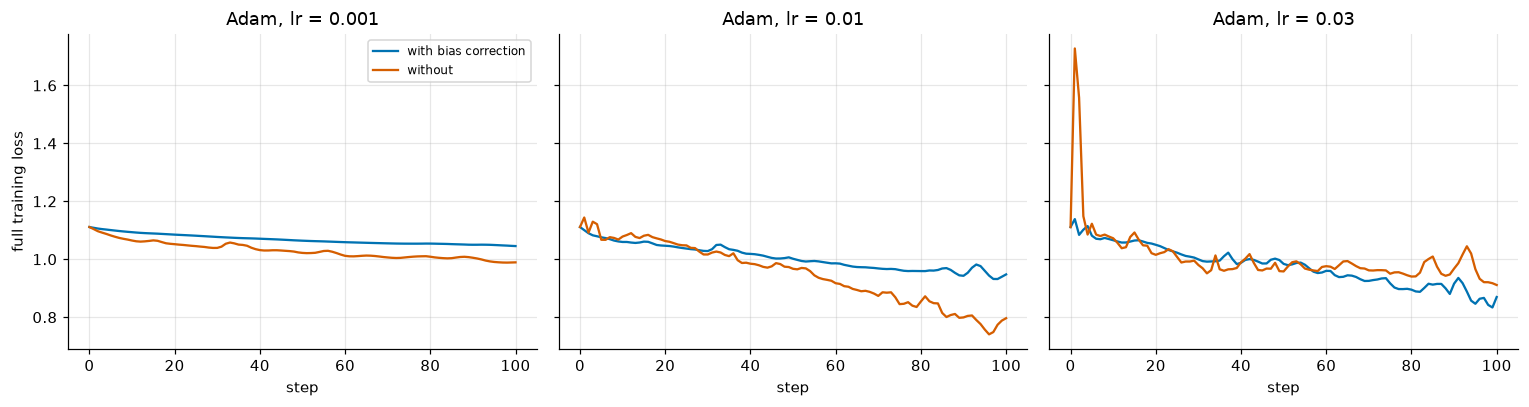

In [29]:
def adam_from_scratch_run(lr, corrected, steps=100, seed=0):
    """Adam written directly from the equations (with or without bias correction); full loss after each step."""
    model = make_mlp(seed)
    params = list(model.parameters())
    m = [torch.zeros_like(p) for p in params]
    v = [torch.zeros_like(p) for p in params]
    gen = torch.Generator().manual_seed(seed)
    losses = [full_loss(model)]
    for t in range(1, steps + 1):
        idx = torch.randint(0, N, (64,), generator=gen)
        model.zero_grad()
        F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
        with torch.no_grad():
            for i, p in enumerate(params):
                m[i] = 0.9 * m[i] + 0.1 * p.grad
                v[i] = 0.999 * v[i] + 0.001 * p.grad**2
                m_hat = m[i] / (1 - 0.9**t) if corrected else m[i]
                v_hat = v[i] / (1 - 0.999**t) if corrected else v[i]
                p -= lr * m_hat / (v_hat.sqrt() + 1e-8)
        losses.append(full_loss(model))
    return losses


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, lr in zip(axes, [1e-3, 1e-2, 3e-2]):
    for corrected, col in [(True, COLORS[0]), (False, COLORS[1])]:
        losses = adam_from_scratch_run(lr, corrected)
        ax.plot(losses, color=col, label="with bias correction" if corrected else "without")
        print(f"lr = {lr}, {'corrected  ' if corrected else 'uncorrected'}: loss after steps 1, 10, 100 = "
              f"{losses[1]:.3f}, {losses[10]:.3f}, {losses[100]:.3f}")
    ax.set_xlabel("step")
    ax.set_title(f"Adam, lr = {lr}")
axes[0].set_ylabel("full training loss")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Without the correction, Adam behaves as if the learning rate were several times larger during the first hundreds of steps. At $\eta = 10^{-3}$ and $10^{-2}$ that happens to *speed up* the early decrease — the corrected runs' learning rates are simply on the small side for this problem. At $\eta = 0.03$ the very first step sends the loss up (to about 1.7 from 1.1), and the uncorrected run is still behind the corrected one after 100 steps. The correction makes $\eta$ mean the same thing from the first step on, so a learning rate tuned on one run length transfers to the start of another; it is not about always being faster.

### Implementing Adam and matching `torch.optim.Adam`

The function above is a direct transcription of the equations. To match PyTorch bit for bit we need its exact sequence of operations. PyTorch (version printed below) computes $\mathbf m$ with `lerp_` (linear interpolation: `m.lerp_(g, w)` sets $m \leftarrow m + w(g - m)$, which equals $(1 - w)m + wg$ in exact arithmetic but rounds differently), divides $\sqrt{\mathbf v_t}$ by $\sqrt{1 - \beta_2^t}$ rather than dividing $\mathbf v_t$ first, and folds $\frac{1}{1 - \beta_1^t}$ into the step size:

In [30]:
def adam_step(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """One Adam step, written with the same operations, in the same order, as torch.optim.Adam."""
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    state["t"] += 1                                    # one step counter for all parameters
    t = state["t"]
    bias_correction1 = 1 - beta1**t
    bias_correction2 = 1 - beta2**t
    with torch.no_grad():
        for p, m, v in zip(params, state["m"], state["v"]):
            g = p.grad
            m.lerp_(g, 1 - beta1)                              # m <- beta1 m + (1 - beta1) g
            v.mul_(beta2).addcmul_(g, g, value=1 - beta2)      # v <- beta2 v + (1 - beta2) g²
            denom = (v.sqrt() / bias_correction2**0.5).add_(eps)   # sqrt(v_hat) + eps
            p.addcdiv_(m, denom, value=-lr / bias_correction1)     # theta <- theta - lr m_hat / denom


print("torch", torch.__version__)
diffs = lockstep(lambda ps: torch.optim.Adam(ps, lr=1e-2), lambda ps, st: adam_step(ps, st, lr=1e-2), steps=300)
print("max |difference| over 300 steps:", max(diffs))
check(max(diffs) == 0.0, "adam_step should match torch.optim.Adam exactly")
passed("adam_step matches torch.optim.Adam bit for bit over 300 steps")

torch 2.14.1


max |difference| over 300 steps: 0.0
✅ adam_step matches torch.optim.Adam bit for bit over 300 steps passed


Exact agreement over 300 steps. (If a future PyTorch version reorders these operations, the differences will be at rounding level at first; the next cell shows how such differences evolve.)

How far apart does the **direct transcription** end up? It is the same algorithm, so the parameters should differ only by rounding — but how much is "only by rounding" after hundreds of steps?

In [31]:
def adam_textbook_step(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """Adam transcribed directly from the equations."""
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    state["t"] += 1
    t = state["t"]
    with torch.no_grad():
        for i, p in enumerate(params):
            state["m"][i] = beta1 * state["m"][i] + (1 - beta1) * p.grad
            state["v"][i] = beta2 * state["v"][i] + (1 - beta2) * p.grad**2
            m_hat = state["m"][i] / (1 - beta1**t)
            v_hat = state["v"][i] / (1 - beta2**t)
            p -= lr * m_hat / (v_hat.sqrt() + eps)


diffs_tb = lockstep(lambda ps: torch.optim.Adam(ps, lr=1e-2), lambda ps, st: adam_textbook_step(ps, st, lr=1e-2), steps=300)
for t in [1, 10, 50, 100, 300]:
    print(f"after {t:>3} steps: max |textbook - torch| = {diffs_tb[t - 1]:.1e}")

after   1 steps: max |textbook - torch| = 6.0e-08
after  10 steps: max |textbook - torch| = 6.0e-08
after  50 steps: max |textbook - torch| = 5.1e-07
after 100 steps: max |textbook - torch| = 1.5e-06
after 300 steps: max |textbook - torch| = 4.0e-01


The differences start at the rounding level ($\sim 10^{-7}$) but **grow**: slowly at first, then by orders of magnitude, to about 0.4 after 300 steps. Training is a long chain of nonlinear updates, and tiny perturbations get amplified; Adam amplifies them further for parameters whose gradients are near zero, where $\hat m/\sqrt{\hat v}$ can change a lot when $g$ changes slightly. Both runs are equally valid trainings; they just follow different paths. The practical lesson for testing an optimizer: compare **a few steps** with a tolerance, or reproduce the reference's operations exactly, as we did.

### Why Adam usually "just works"

Three properties, each easy to verify, explain much of Adam's reputation for working with little tuning:

1. **The step size is set by $\eta$, not by the gradient's size.** At $t = 1$, $\hat{\mathbf m}_1 = \mathbf g_1$ and $\hat{\mathbf v}_1 = \mathbf g_1^2$, so the first update is $-\eta\,\mathbf g_1/(|\mathbf g_1| + \varepsilon) \approx -\eta\operatorname{sign}(\mathbf g_1)$. Later, $|\hat m|/\sqrt{\hat v}$ is close to 1 when a parameter's gradient keeps a steady value and well below 1 when it fluctuates in sign, since the fluctuations cancel in $\hat m$ but not in $\hat v$. Roughly, every parameter moves by at most about $\eta$ per step (Kingma and Ba, Section 2.1, give the precise bounds). So $\eta$ is a trust region in parameter units: $10^{-3}$ means "change each weight by about $0.001$ per step".
2. **Invariance to rescaling the loss.** Multiplying the loss by $c > 0$ multiplies every gradient by $c$, $\hat{\mathbf m}$ by $c$ and $\sqrt{\hat{\mathbf v}}$ by $c$: the update is unchanged (apart from $\varepsilon$). Plain SGD's update is multiplied by $c$.
3. **Momentum and per-parameter scaling together**, with defaults ($\beta_1, \beta_2, \varepsilon$) that rarely need changing — leaving one hyperparameter, $\eta$, to tune.

The second property, tested by training for 20 steps with the loss multiplied by 1000:

In [32]:
for name, make_opt in [("SGD (lr = 0.1)", lambda ps: torch.optim.SGD(ps, lr=0.1)),
                       ("Adam (lr = 0.01)", lambda ps: torch.optim.Adam(ps, lr=1e-2))]:
    finals = []
    for scale in [1.0, 1000.0]:
        model = make_mlp(0)
        opt = make_opt(model.parameters())
        gen = torch.Generator().manual_seed(0)
        for idx in shuffled_batches(N, 64, gen)[:20]:
            opt.zero_grad()
            (scale * F.cross_entropy(model(X_sp[idx]), y_sp[idx])).backward()
            opt.step()
        finals.append(torch.cat([p.detach().reshape(-1) for p in model.parameters()]))
        print(f"{name:17s} loss × {scale:>6}: unscaled training loss after 20 steps = {full_loss(model):.4f}, "
              f"||θ|| = {finals[-1].norm().item():.4g}")
    print(f"{'':17s} max |θ(×1000) - θ(×1)| = {(finals[1] - finals[0]).abs().max().item():.1e}")

SGD (lr = 0.1)    loss ×    1.0: unscaled training loss after 20 steps = 1.0945, ||θ|| = 7.409
SGD (lr = 0.1)    loss × 1000.0: unscaled training loss after 20 steps = 52.9934, ||θ|| = 1.648e+09
                  max |θ(×1000) - θ(×1)| = 1.6e+09
Adam (lr = 0.01)  loss ×    1.0: unscaled training loss after 20 steps = 1.0583, ||θ|| = 8.428
Adam (lr = 0.01)  loss × 1000.0: unscaled training loss after 20 steps = 1.0583, ||θ|| = 8.428
                  max |θ(×1000) - θ(×1)| = 4.1e-02


With SGD, the scaled loss gives steps 1000 times larger and training blows up ($\|\boldsymbol\theta\|$ in the billions). With Adam, the training loss and $\|\boldsymbol\theta\|$ agree to all printed digits. Individual parameters still differ by up to about 0.04: $\varepsilon$ is not scaled, so each update changes by a relative amount of order $\varepsilon/\sqrt{\hat v}$ (about $10^{-4}$ here, where $\sqrt{\hat v}$ is typically below $10^{-4}$), and such small differences grow during training, as we just saw. In a network, the "scale" of the gradient differs between layers, between tasks, and over training. Adam absorbs these differences; SGD needs its learning rate re-tuned.

Adam is not always the best choice: well-tuned SGD with momentum is still standard for some vision models, and adaptive methods have been reported to generalize worse in some settings (Wilson et al. 2017, "The Marginal Value of Adaptive Gradient Methods in Machine Learning"). Section 7 compares optimizers on our task.

### Checkpoint 4.1

A single parameter receives the gradients $g_1 = 2$ and $g_2 = -1$. With $\beta_1 = 0.9$, $\beta_2 = 0.999$, compute by hand `m_hat2` and `v_hat2`, the bias-corrected moments after the second step, and `step1`, the first update for $\eta = 0.01$ (ignore $\varepsilon$).

<details>
<summary><b>💡 Hint</b></summary>

$m_1 = 0.2$, $m_2 = 0.9 \cdot 0.2 + 0.1 \cdot (-1) = 0.08$, and $1 - \beta_1^2 = 0.19$. $v_1 = 0.004$, $v_2 = 0.999 \cdot 0.004 + 0.001 \cdot 1$, and $1 - \beta_2^2 = 0.001999$. The first update is $-\eta \operatorname{sign}(g_1)$.

</details>

In [33]:
m_hat2 = (0.9 * 0.1 * 2 + 0.1 * -1) / (1 - 0.9**2)
v_hat2 = (0.999 * 0.001 * 4 + 0.001 * 1) / (1 - 0.999**2)
step1 = -0.01
print(m_hat2, v_hat2, step1)

0.42105263157894757 2.4992496248124403 -0.01


In [34]:
_p = torch.zeros(1, requires_grad=True, dtype=f64)
_opt = torch.optim.Adam([_p], lr=0.01)
_p.grad = torch.full((1,), 2.0, dtype=f64)
_opt.step()
check_close(step1, _p.item(), "step1")
_p.grad = torch.full((1,), -1.0, dtype=f64)
_opt.step()
_st = _opt.state[_p]
check_close(m_hat2, (_st["exp_avg"] / (1 - 0.9**2)).item(), "m_hat2")
check_close(v_hat2, (_st["exp_avg_sq"] / (1 - 0.999**2)).item(), "v_hat2")
passed("Checkpoint 4.1")

✅ Checkpoint 4.1 passed


## 5. Weight decay: L2 penalty versus decoupled decay

A common way to keep weights small (regularization, Chapter 4; notebook 09 met it to tame separable data) is to add an **L2 penalty** to the loss:

$$L_{\text{reg}}(\boldsymbol\theta) = L(\boldsymbol\theta) + \frac\lambda2\|\boldsymbol\theta\|^2, \qquad \nabla L_{\text{reg}} = \mathbf g + \lambda\boldsymbol\theta.$$

**For plain SGD**, a step on $L_{\text{reg}}$ is

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta(\mathbf g + \lambda\boldsymbol\theta) = (1 - \eta\lambda)\,\boldsymbol\theta - \eta\,\mathbf g:$$

shrink every weight by the factor $1 - \eta\lambda$, then take an ordinary gradient step. Shrinking the weights directly is called **weight decay**; for SGD the two are the same algorithm, with the decay rate per step equal to $\eta\lambda$. (So the per-step shrinkage depends on the learning rate: halving $\eta$ halves the decay unless $\lambda$ is doubled.) `torch.optim.SGD(..., weight_decay=λ)` implements it by adding $\lambda\boldsymbol\theta$ to the gradient. Three ways to train with the same regularization, checked against each other:

In [35]:
def sgd_three_ways(lr, lam, steps=50, seed=0):
    """Returns the final parameters of: (a) L2 penalty in the loss; (b) SGD(weight_decay=lam); (c) decay then step."""
    results = []
    for way in ["penalty", "weight_decay arg", "decoupled"]:
        model = make_mlp(seed)
        params = list(model.parameters())
        opt = torch.optim.SGD(params, lr=lr, weight_decay=lam if way == "weight_decay arg" else 0.0)
        gen = torch.Generator().manual_seed(seed)
        for _ in range(steps):
            idx = torch.randint(0, N, (64,), generator=gen)
            opt.zero_grad()
            loss = F.cross_entropy(model(X_sp[idx]), y_sp[idx])
            if way == "penalty":
                loss = loss + lam / 2 * sum((p**2).sum() for p in params)
            loss.backward()
            if way == "decoupled":
                with torch.no_grad():
                    for p in params:
                        p.mul_(1 - lr * lam)             # shrink by (1 - ηλ), outside the gradient
            opt.step()
        results.append(torch.cat([p.detach().reshape(-1) for p in params]))
    return results


a, b, c = sgd_three_ways(lr=0.1, lam=1e-2)
print(f"max |penalty - weight_decay arg| = {(a - b).abs().max().item():.1e}")
print(f"max |penalty - decoupled|        = {(a - c).abs().max().item():.1e}")
print(f"(compare: total change of the parameters over training = {(a - torch.cat([p.detach().reshape(-1) for p in make_mlp(0).parameters()])).abs().max().item():.2f})")

max |penalty - weight_decay arg| = 3.0e-08
max |penalty - decoupled|        = 7.7e-07
(compare: total change of the parameters over training = 0.05)


All three agree to `float32` rounding. (The equivalence holds for plain SGD. With momentum it no longer holds exactly: the penalty's gradient $\lambda\boldsymbol\theta$ enters the velocity and is accumulated, while a decay applied directly to $\boldsymbol\theta$ is not.)

### Adam: the two are different

Put the L2 gradient through Adam (`torch.optim.Adam(..., weight_decay=λ)` does exactly this): $\tilde{\mathbf g} = \mathbf g + \lambda\boldsymbol\theta$ is fed into both moving averages, and the update divides it by $\sqrt{\hat{\mathbf v}} + \varepsilon$. The decay term is therefore **rescaled per parameter**: a parameter with a large gradient history (large $\hat v$) is barely decayed, while a parameter with tiny gradients gets a decay step of size up to $\eta$ — the same size as its data-driven steps, whatever $\lambda$ is.

**Decoupled weight decay** (Loshchilov and Hutter 2019, "Decoupled Weight Decay Regularization", ICLR) restores the SGD behaviour by shrinking the parameters *outside* the adaptive update. PyTorch's `torch.optim.AdamW` performs, at each step,

$$\boldsymbol\theta \leftarrow (1 - \eta\lambda)\,\boldsymbol\theta, \qquad\text{then the Adam update with the raw gradient } \mathbf g,$$

so every parameter shrinks by the same factor, and the moments $\mathbf m, \mathbf v$ never see $\lambda\boldsymbol\theta$. (In the paper the decay is scaled by a schedule multiplier rather than by $\eta$ itself; PyTorch multiplies by the learning rate, so `weight_decay` values are not interchangeable between libraries without checking.) Implementing AdamW is Problem 2 of this chapter's problem set; here we use `torch.optim.AdamW` and look at the consequences.

First, a two-parameter toy problem where the difference is stark. The loss $L = \frac12\sum_i c_i(\theta_i - 1)^2$ pulls both parameters toward 1, but with curvatures $c = (100, 0.01)$: the first parameter's gradients are 10,000 times larger. With $\lambda = 0.5$, Adam with the L2 penalty should converge to a minimizer of $L_{\text{reg}}$, which solves $c_i(\theta_i - 1) + \lambda\theta_i = 0$, i.e. $\theta_i^* = c_i/(c_i + \lambda)$.

In [36]:
c_toy = torch.tensor([100.0, 0.01])
lam_toy = 0.5
print("L2-regularized minimizer c/(c + λ):", (c_toy / (c_toy + lam_toy)).tolist())
for name, opt_class in [("Adam(weight_decay=0.5) ", torch.optim.Adam), ("AdamW(weight_decay=0.5)", torch.optim.AdamW)]:
    theta = torch.zeros(2, requires_grad=True)
    opt = opt_class([theta], lr=1e-2, weight_decay=lam_toy)
    for _ in range(20000):
        opt.zero_grad()
        (0.5 * (c_toy * (theta - 1) ** 2).sum()).backward()
        opt.step()
    print(f"{name}: θ after 20,000 steps = {[round(v, 4) for v in theta.tolist()]}")

L2-regularized minimizer c/(c + λ): [0.9950248599052429, 0.019607843831181526]


Adam(weight_decay=0.5) : θ after 20,000 steps = [0.995, 0.0196]


AdamW(weight_decay=0.5): θ after 20,000 steps = [0.9999, 0.9999]


Adam with the L2 penalty finds the regularized minimizer: the weakly-constrained second parameter is shrunk from 1 to 0.02, the stiff first one barely moves. AdamW leaves **both** near 1. Its decay of $\eta\lambda\theta$ per step is balanced by the normalized Adam step, which is up to $\eta$ in size however small the raw gradient is; so even the gradient $0.01(\theta_2 - 1)$ holds $\theta_2$ near its target. AdamW therefore does **not** minimize $L + \frac\lambda2\|\boldsymbol\theta\|^2$: it is a different regularizer, which shrinks parameters relative to how consistently their gradients push back, not how hard.

Now the MLP on the spirals, with Adam at $\eta = 3\times10^{-3}$ for 30 epochs, without decay and with both kinds at the same $\lambda = 10^{-2}$ (AdamW's default value):

Adam, no decay                        : final loss 0.1596, final ||θ|| = 31.94


Adam(weight_decay=1e-2)  [L2]         : final loss 1.0545, final ||θ|| = 2.46


AdamW(weight_decay=1e-2) [decoupled]  : final loss 0.1623, final ||θ|| = 31.41


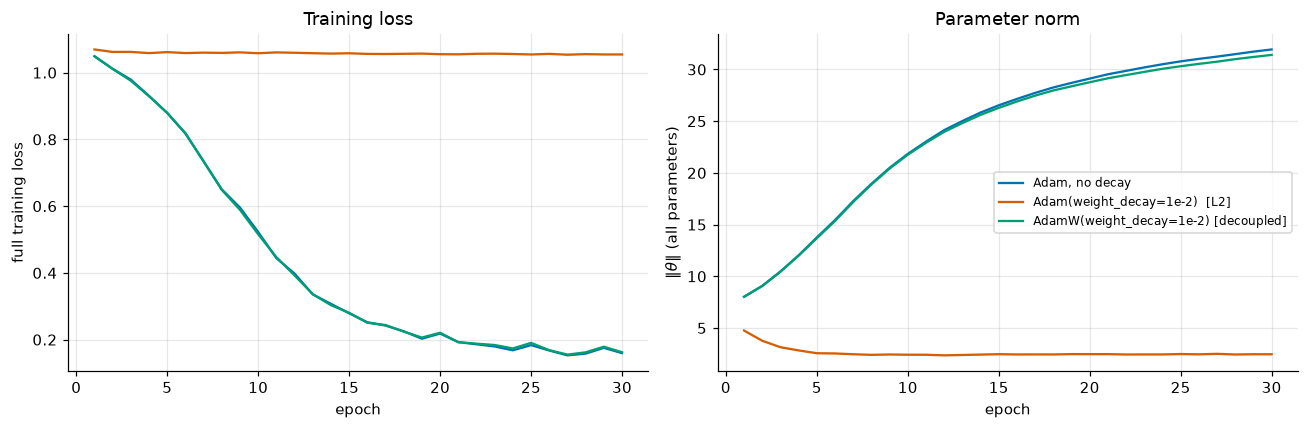

In [37]:
def train_record_norm(make_opt, epochs=30, seed=0):
    """Mini-batch training (B = 64); returns (full loss after each epoch, parameter norm after each epoch)."""
    model = make_mlp(seed)
    opt = make_opt(model.parameters())
    gen = torch.Generator().manual_seed(seed)
    losses, norms = [], []
    for _ in range(epochs):
        for idx in shuffled_batches(N, 64, gen):
            opt.zero_grad()
            F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
            opt.step()
        losses.append(full_loss(model))
        norms.append(torch.cat([p.detach().reshape(-1) for p in model.parameters()]).norm().item())
    return losses, norms


wd_runs = {"Adam, no decay": lambda ps: torch.optim.Adam(ps, lr=3e-3),
           "Adam(weight_decay=1e-2)  [L2]": lambda ps: torch.optim.Adam(ps, lr=3e-3, weight_decay=1e-2),
           "AdamW(weight_decay=1e-2) [decoupled]": lambda ps: torch.optim.AdamW(ps, lr=3e-3, weight_decay=1e-2)}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for k, (name, make_opt) in enumerate(wd_runs.items()):
    losses, norms = train_record_norm(make_opt)
    print(f"{name:38s}: final loss {losses[-1]:.4f}, final ||θ|| = {norms[-1]:.2f}")
    ax1.plot(range(1, 31), losses, color=COLORS[k], label=name)
    ax2.plot(range(1, 31), norms, color=COLORS[k], label=name)
ax1.set_xlabel("epoch")
ax1.set_ylabel("full training loss")
ax1.set_title("Training loss")
ax2.set_xlabel("epoch")
ax2.set_ylabel("$\\|\\theta\\|$ (all parameters)")
ax2.set_title("Parameter norm")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Same nominal $\lambda$, completely different behaviour. With the L2 penalty inside Adam, the norm collapses to about 2.5 and the network cannot fit the spirals (loss near $\ln 3$): every parameter whose data gradient is small is pushed toward zero at a rate of order $\eta$ per step. AdamW's decay, $1 - \eta\lambda = 1 - 3\times10^{-5}$ per step, trims the norm slightly and leaves the fit intact. Neither is "right" in general — they are different regularizers that need different $\lambda$ — but the decoupled form behaves like the familiar SGD weight decay, and its strength does not depend on each parameter's gradient history. AdamW has become the standard choice for training large networks, including Transformers (Chapter 9).

### Checkpoint 5.1

1. `shrink_sgd`: plain SGD with `lr=0.05` and `weight_decay=4e-4` multiplies each weight by what factor per step (before the gradient step)?
2. `wd_adamw`: what `weight_decay` gives `torch.optim.AdamW` with `lr=1e-3` the **same** per-step shrink factor?

<details>
<summary><b>💡 Hint</b></summary>

Both multiply by $1 - \eta\lambda$. Set $10^{-3}\,\lambda_{\text{AdamW}} = 0.05 \times 4\times10^{-4}$.

</details>

In [38]:
shrink_sgd = 1 - 0.05 * 4e-4
wd_adamw = 0.05 * 4e-4 / 1e-3
print(shrink_sgd, wd_adamw)

0.99998 0.02


In [39]:
_p = torch.ones(1, requires_grad=True)
_opt = torch.optim.SGD([_p], lr=0.05, weight_decay=4e-4)
_p.grad = torch.zeros(1)
_opt.step()
check_close(shrink_sgd, _p.item(), "shrink_sgd", rtol=1e-7, atol=0)
_q = torch.ones(1, requires_grad=True, dtype=f64)
_optw = torch.optim.AdamW([_q], lr=1e-3, weight_decay=wd_adamw)
_q.grad = torch.zeros(1, dtype=f64)
_optw.step()
check_close(_q.item(), 1 - 0.05 * 4e-4, "AdamW shrink factor with your wd_adamw", rtol=1e-10, atol=0)
passed("Checkpoint 5.1")

✅ Checkpoint 5.1 passed


## 6. Learning-rate schedules

A constant learning rate is a compromise. Early in training we want large steps to make progress; late in training, mini-batch noise keeps the parameters bouncing around the minimum with an amplitude that scales with $\eta$ (Section 1), so we want small steps to settle. A **schedule** changes $\eta$ over training. PyTorch's `torch.optim.lr_scheduler` provides them; each scheduler rewrites `optimizer.param_groups[k]["lr"]` when you call `scheduler.step()`. Common shapes, for a run of $T$ steps with base rate $\eta_0$:

- **Step decay** (`StepLR`): multiply by $\gamma$ (e.g. 0.1) every fixed number of steps.
- **Cosine** (`CosineAnnealingLR`, Loshchilov and Hutter 2017, "SGDR"): $\eta_t = \eta_{\min} + \frac12(\eta_0 - \eta_{\min})\big(1 + \cos\frac{\pi t}{T}\big)$, a smooth decay from $\eta_0$ to $\eta_{\min}$.
- **Linear warmup**: ramp from a small fraction of $\eta_0$ up to $\eta_0$ over the first $W$ steps (`LinearLR`), usually followed by a decay — e.g. warmup then cosine, chained with `SequentialLR` or written as one function with `LambdaLR`.

max |SequentialLR - LambdaLR| = 1.1e-16


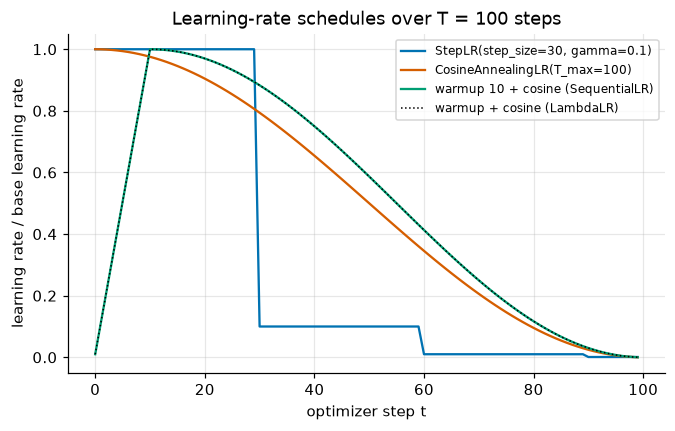

In [40]:
from torch.optim.lr_scheduler import CosineAnnealingLR, LambdaLR, LinearLR, SequentialLR, StepLR

T, W = 100, 10


def lr_trace(make_sched, steps=T):
    """Learning rate used at each of `steps` optimizer steps, for a scheduler built by make_sched(opt)."""
    p = torch.zeros(1, requires_grad=True)
    opt = torch.optim.SGD([p], lr=1.0)                 # base lr 1, so the trace is the multiplier
    sched = make_sched(opt)
    used = []
    for _ in range(steps):
        used.append(opt.param_groups[0]["lr"])
        p.grad = torch.zeros(1)
        opt.step()
        sched.step()                                    # after optimizer.step()
    return used


def warmup_cosine(t):
    """Multiplier: linear warmup from 0.01 to 1 over W steps, then cosine decay to 0 at step T."""
    if t < W:
        return 0.01 + 0.99 * t / W
    return 0.5 * (1 + math.cos(math.pi * (t - W) / (T - W)))


schedules = {
    "StepLR(step_size=30, gamma=0.1)": lambda o: StepLR(o, step_size=30, gamma=0.1),
    "CosineAnnealingLR(T_max=100)": lambda o: CosineAnnealingLR(o, T_max=T),
    "warmup 10 + cosine (SequentialLR)": lambda o: SequentialLR(
        o, [LinearLR(o, start_factor=0.01, end_factor=1.0, total_iters=W), CosineAnnealingLR(o, T_max=T - W)], milestones=[W]),
    "warmup 10 + cosine (LambdaLR)": lambda o: LambdaLR(o, warmup_cosine),
}
traces = {name: lr_trace(make) for name, make in schedules.items()}
seq, lam_trace = traces["warmup 10 + cosine (SequentialLR)"], traces["warmup 10 + cosine (LambdaLR)"]
print(f"max |SequentialLR - LambdaLR| = {max(abs(a - b) for a, b in zip(seq, lam_trace)):.1e}")

fig, ax = plt.subplots(figsize=(7, 4))
for k, (name, tr) in enumerate(list(traces.items())[:3]):
    ax.plot(tr, color=COLORS[k], label=name)
ax.plot(lam_trace, ":", color="k", lw=1, label="warmup + cosine (LambdaLR)")
ax.set_xlabel("optimizer step t")
ax.set_ylabel("learning rate / base learning rate")
ax.set_title("Learning-rate schedules over T = 100 steps")
ax.legend(fontsize=8)
plt.show()

Step decay drops abruptly at steps 30, 60 and 90; cosine decays slowly at first and last, fastest in the middle; warmup + cosine rises linearly over 10 steps and then follows a cosine down to zero. The chained `SequentialLR` and the hand-written `LambdaLR` function produce the same multipliers (to rounding), so either style works; `LambdaLR` makes the formula explicit. In real training, $T$ is the total number of optimizer steps (or epochs, if you call `scheduler.step()` once per epoch — be consistent).

### Where `scheduler.step()` goes

Since PyTorch 1.1 the order is `optimizer.step()` **then** `scheduler.step()`. Calling the scheduler first silently skips the first value of the schedule; PyTorch detects it and warns:

In [41]:
for order in ["optimizer then scheduler", "scheduler then optimizer"]:
    p = torch.zeros(1, requires_grad=True)
    opt = torch.optim.SGD([p], lr=1.0)
    sched = StepLR(opt, step_size=2, gamma=0.1)
    used = []
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        for _ in range(5):
            p.grad = torch.ones(1)
            if order == "scheduler then optimizer":
                sched.step()
            used.append(opt.param_groups[0]["lr"])      # the lr the optimizer step will use
            opt.step()
            if order == "optimizer then scheduler":
                sched.step()
    print(f"{order}: learning rates used = {[round(u, 4) for u in used]}")
    for w in caught:
        print("   warning:", str(w.message)[:110], "...")

optimizer then scheduler: learning rates used = [1.0, 1.0, 0.1, 0.1, 0.01]
scheduler then optimizer: learning rates used = [1.0, 0.1, 0.1, 0.01, 0.01]


With the correct order the rate stays at 1.0 for two steps and then drops, as specified. With the wrong order, the first step already uses 0.1: the schedule is shifted by one step — harmless for a long run with a smooth schedule, wrong for warmup (whose first, smallest value is skipped) and confusing when reproducing results.

### Why warmup, especially for Adam? (intuition)

Section 4 showed that Adam's first update is $-\eta\operatorname{sign}(\mathbf g_1)$: **every** parameter moves by the full $\eta$, based on a single mini-batch, and in the early steps $\hat{\mathbf v}_t$ averages only a handful of noisy squared gradients, so the per-parameter step sizes $\eta/\sqrt{\hat{\mathbf v}_t}$ are themselves noisy. Let us measure how many parameters take near-maximal steps:

In [42]:
model = make_mlp(0)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(0)
for t in range(1, 201):
    idx = torch.randint(0, N, (64,), generator=gen)
    before = [p.detach().clone() for p in model.parameters()]
    opt.zero_grad()
    F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
    opt.step()
    if t in (1, 2, 10, 50, 200):
        moves = torch.cat([(p.detach() - b).abs().reshape(-1) for p, b in zip(model.parameters(), before)]) / 1e-3
        moved = moves[moves > 0]
        print(f"step {t:>3}: fraction of parameters moving more than 0.9 η: {(moved > 0.9).float().mean().item():.3f}, "
              f"median |step|/η = {moved.median().item():.3f}")

step   1: fraction of parameters moving more than 0.9 η: 0.996, median |step|/η = 1.000
step   2: fraction of parameters moving more than 0.9 η: 0.387, median |step|/η = 0.806
step  10: fraction of parameters moving more than 0.9 η: 0.024, median |step|/η = 0.484


step  50: fraction of parameters moving more than 0.9 η: 0.112, median |step|/η = 0.300
step 200: fraction of parameters moving more than 0.9 η: 0.046, median |step|/η = 0.219


At step 1 every parameter (with a nonzero gradient) moves by essentially $\eta$; over the following steps, as $\hat{\mathbf v}$ accumulates information, the typical step shrinks to a fraction of $\eta$ and only parameters with consistent gradients keep taking large steps. Warmup keeps $\eta$ small during this phase, so the noisy early steps cannot do much damage. Liu et al. (2020, "On the Variance of the Adaptive Learning Rate and Beyond", ICLR) analyse the variance of the adaptive step size in early training along these lines and propose RAdam, which corrects for it; treat this account as intuition rather than a complete explanation. Warmup is standard for Transformers (it was part of the original recipe, Vaswani et al. 2017) and for large-batch training. On small networks it often makes little difference (we do not test it here) — a schedule is a tool for specific problems, not a ritual.

### Checkpoint 6.1

Write `warmup_linear(t)`, a multiplier for `LambdaLR` with a run of `T = 100` steps: linear warmup from 0 at $t = 0$ to 1 at $t = 20$, then linear decay from 1 at $t = 20$ to 0 at $t = 100$ (a common schedule for fine-tuning language models).

<details>
<summary><b>💡 Hint</b></summary>

For $t < 20$ return `t / 20`; otherwise return `(100 - t) / (100 - 20)`. Both pieces give 1 at $t = 20$.

</details>

In [43]:
def warmup_linear(t):
    if t < 20:
        return t / 20
    return (100 - t) / (100 - 20)

In [44]:
_tr = lr_trace(lambda o: LambdaLR(o, warmup_linear))
check_close(torch.tensor(_tr), torch.tensor([min(t / 20, (100 - t) / 80) for t in range(100)]), "learning rates from warmup_linear")
check_close(warmup_linear(20), 1.0, "warmup_linear(20)")
check_close(warmup_linear(100), 0.0, "warmup_linear(100)")
passed("Checkpoint 6.1")

✅ Checkpoint 6.1 passed


### The learning-rate range test

How do we find a good $\eta$ to begin with? A cheap heuristic is the **learning-rate range test** (Smith 2017, "Cyclical Learning Rates for Training Neural Networks"): run one short training job in which the learning rate grows exponentially at every step, from far too small to far too large, and plot the loss against the learning rate. At first the loss barely moves (steps too small), then it falls (useful range), then it explodes (too large). A common rule of thumb is to pick a rate somewhat below the point of fastest decrease — about a tenth of where the loss is lowest. Its assumptions: the loss during this short, ever-accelerating run reflects how a *fixed* learning rate would behave over a full run, and the best rate does not depend much on training length or on a schedule. Neither is guaranteed, so treat the result as a starting point for a proper search (notebook 26), not an answer; Section 7 shows a case where the rule is off by almost a factor of 10.

Adam: lowest smoothed loss 0.924 at lr = 0.058; rule-of-thumb suggestion ≈ 0.0058


SGD: lowest smoothed loss 1.075 at lr = 1.3; rule-of-thumb suggestion ≈ 0.13


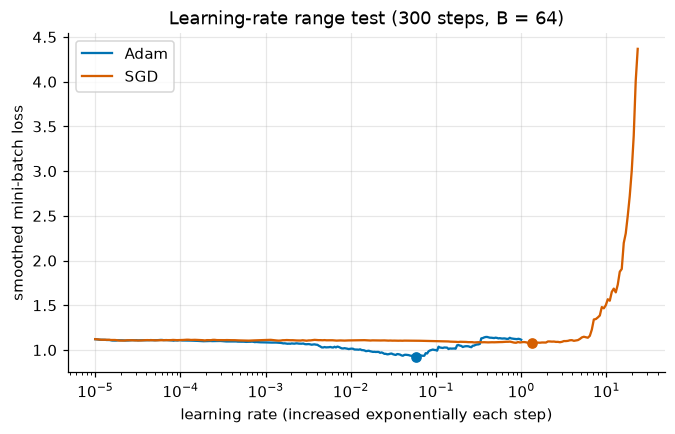

In [45]:
def lr_range_test(make_opt, lr_min=1e-5, lr_max=1.0, steps=300, seed=0):
    """Exponentially increasing lr over `steps` mini-batch steps. Returns (lrs, smoothed batch losses)."""
    model = make_mlp(seed)
    opt = make_opt(model.parameters(), lr_min)
    gen = torch.Generator().manual_seed(seed)
    factor = (lr_max / lr_min) ** (1 / (steps - 1))
    lrs, smoothed, avg = [], [], None
    for t in range(steps):
        lr = lr_min * factor**t
        for group in opt.param_groups:
            group["lr"] = lr
        idx = torch.randint(0, N, (64,), generator=gen)
        opt.zero_grad()
        loss = F.cross_entropy(model(X_sp[idx]), y_sp[idx])
        loss.backward()
        opt.step()
        avg = loss.item() if avg is None else 0.9 * avg + 0.1 * loss.item()   # smooth the noisy batch losses
        lrs.append(lr)
        smoothed.append(avg)
        if not math.isfinite(avg) or avg > 4 * min(smoothed):                 # stop once it has clearly blown up
            break
    return lrs, smoothed


fig, ax = plt.subplots(figsize=(7, 4))
range_results = {}
for k, (name, make_opt) in enumerate([("Adam", lambda ps, lr: torch.optim.Adam(ps, lr=lr)),
                                      ("SGD", lambda ps, lr: torch.optim.SGD(ps, lr=lr))]):
    lrs, sm = lr_range_test(make_opt, lr_max=1.0 if name == "Adam" else 100.0)
    best = min(range(len(sm)), key=lambda i: sm[i])
    range_results[name] = lrs[best]
    print(f"{name}: lowest smoothed loss {sm[best]:.3f} at lr = {lrs[best]:.2g}; rule-of-thumb suggestion ≈ {lrs[best] / 10:.2g}")
    ax.semilogx(lrs, sm, color=COLORS[k], label=name)
    ax.plot([lrs[best]], [sm[best]], "o", color=COLORS[k])
ax.set_xlabel("learning rate (increased exponentially each step)")
ax.set_ylabel("smoothed mini-batch loss")
ax.set_title("Learning-rate range test (300 steps, B = 64)")
ax.legend()
plt.show()

Adam's curve shows the three phases clearly: flat up to about $10^{-3}$, falling to a minimum near $0.06$, rising beyond (only mildly within our range, so the stopping rule never triggered). SGD's curve is less informative: 300 steps are too few for SGD to make much progress at any rate, so it shows only a shallow dip near $1$ before exploding above about $5$. Both say that "the learning rate" means very different things for different optimizers. Section 7 tunes both properly, and we can check the suggestions against it.

## 7. Comparing optimizers fairly

Which optimizer is best? The question is meaningless without saying **how each one was tuned**. An optimizer run at somebody else's learning rate is not being tested; its learning rate is. We train the same MLP on the spirals with five optimizers — SGD, SGD with momentum 0.9, RMSProp, Adam and AdamW ($\lambda = 10^{-2}$) — each over a grid of five or six learning rates spaced by about a factor of 3 (extended until the best value is not at the edge of the grid), three seeds each (seed = initialization and batch order), for 20 epochs with $B = 64$: 84 runs.

In [46]:
def train_curve(make_opt, lr, seed, epochs=20, batch_size=64):
    """Full training loss after each epoch (epoch 0 = initialization)."""
    model = make_mlp(seed)
    opt = make_opt(model.parameters(), lr)
    gen = torch.Generator().manual_seed(seed)
    curve = [full_loss(model)]
    for _ in range(epochs):
        for idx in shuffled_batches(N, batch_size, gen):
            opt.zero_grad()
            F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
            opt.step()
        curve.append(full_loss(model))
        if not math.isfinite(curve[-1]):
            curve += [float("inf")] * (epochs + 1 - len(curve))
            break
    return curve


optimizers = {
    "SGD": (lambda ps, lr: torch.optim.SGD(ps, lr=lr), [0.03, 0.1, 0.3, 1.0, 3.0]),
    "SGD + momentum 0.9": (lambda ps, lr: torch.optim.SGD(ps, lr=lr, momentum=0.9), [0.003, 0.01, 0.03, 0.1, 0.3]),
    "RMSProp": (lambda ps, lr: torch.optim.RMSprop(ps, lr=lr), [3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1]),
    "Adam": (lambda ps, lr: torch.optim.Adam(ps, lr=lr), [3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1]),
    "AdamW (wd 1e-2)": (lambda ps, lr: torch.optim.AdamW(ps, lr=lr, weight_decay=1e-2), [3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1]),
}
seeds = [0, 1, 2]
t0 = time.perf_counter()
curves = {}   # (optimizer, lr) -> tensor (seeds, epochs + 1)
for name, (make_opt, lrs) in optimizers.items():
    for lr in lrs:
        curves[(name, lr)] = torch.tensor([train_curve(make_opt, lr, s) for s in seeds])
print(f"{len(curves) * len(seeds)} runs in {time.perf_counter() - t0:.1f} s")

print(f"{'optimizer':20s}" + "".join(f"{'lr #' + str(i + 1):>9}" for i in range(6)) + "    best lr")
best_lr = {}
for name, (_, lrs) in optimizers.items():
    finals = [curves[(name, lr)][:, -1].mean().item() for lr in lrs]
    best_lr[name] = lrs[min(range(len(lrs)), key=lambda i: finals[i])]
    print(f"{name:20s}" + "".join(f"{f:9.3f}" for f in finals) + " " * 9 * (6 - len(finals)) + f"    {best_lr[name]:g}")
print("(mean final training loss over 3 seeds; lr grids as listed in the code)")

84 runs in 32.1 s
optimizer               lr #1    lr #2    lr #3    lr #4    lr #5    lr #6    best lr
SGD                     1.054    1.027    0.895    0.755    1.039             1
SGD + momentum 0.9      1.054    1.027    0.869    0.256    0.519             0.1
RMSProp                 0.981    0.728    0.287    0.254    0.294    0.657    0.01
Adam                    0.975    0.718    0.232    0.226    0.252    0.506    0.01
AdamW (wd 1e-2)         0.975    0.723    0.234    0.247    0.223    0.532    0.03
(mean final training loss over 3 seeds; lr grids as listed in the code)


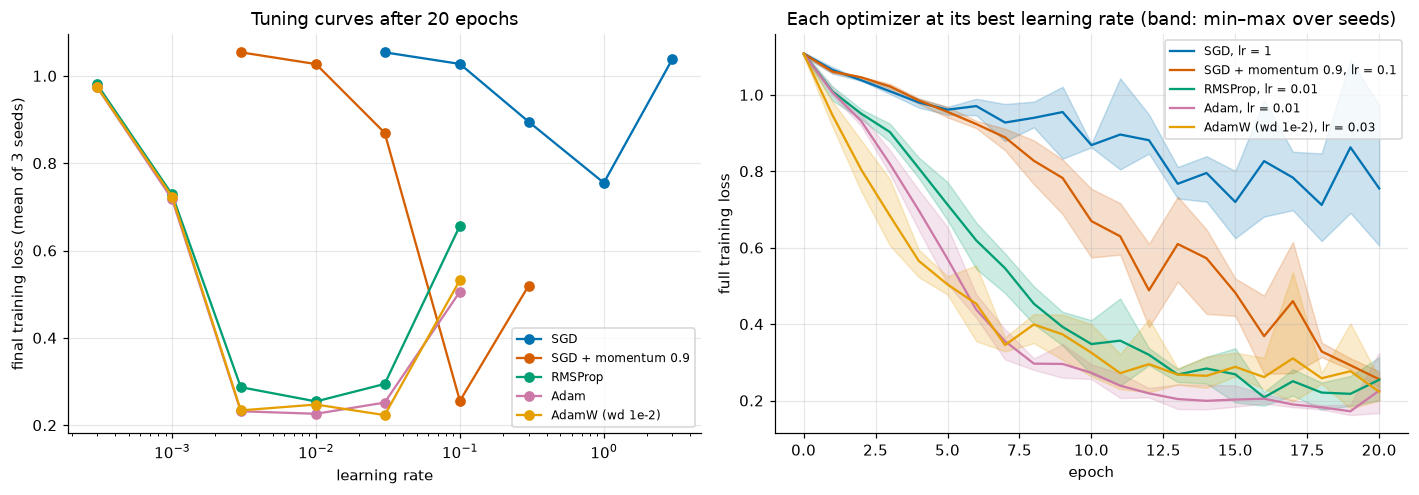

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for k, (name, (_, lrs)) in enumerate(optimizers.items()):
    finals = torch.stack([curves[(name, lr)][:, -1] for lr in lrs])            # (lrs, seeds)
    finals = finals.clamp(max=3.0)                                             # diverged runs drawn at 3
    ax1.semilogx(lrs, finals.mean(dim=1), "o-", color=COLORS[k], label=name)
    c = curves[(name, best_lr[name])]
    ax2.plot(c.mean(dim=0), color=COLORS[k], label=f"{name}, lr = {best_lr[name]:g}")
    ax2.fill_between(range(c.shape[1]), c.min(dim=0).values, c.max(dim=0).values, color=COLORS[k], alpha=0.2)
ax1.set_xlabel("learning rate")
ax1.set_ylabel("final training loss (mean of 3 seeds)")
ax1.set_title("Tuning curves after 20 epochs")
ax1.legend(fontsize=8)
ax2.set_xlabel("epoch")
ax2.set_ylabel("full training loss")
ax2.set_title("Each optimizer at its best learning rate (band: min–max over seeds)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Left: every optimizer has a U-shaped tuning curve, and the best learning rates differ by a factor of about 100: 1 for SGD, 0.1 for SGD with momentum (consistent with momentum's effective rate $\eta/(1-\beta) = 10\eta$), and 0.01–0.03 for the adaptive methods, whose curves are also much flatter near the optimum (Adam stays within 0.03 of its best loss from $3\times10^{-3}$ to $3\times10^{-2}$). Right: at their own best learning rates, momentum SGD, RMSProp, Adam and AdamW end within the seed bands of each other, although the adaptive methods get there much sooner (by epoch 7 they are near 0.35–0.55, momentum SGD still near 0.9); plain SGD is clearly behind and varies most between seeds. Here is the same experiment if we had used one "reasonable" learning rate, $10^{-3}$, for everyone (taking it from the grids where available):

In [48]:
for name, (make_opt, lrs) in optimizers.items():
    at_1e3 = curves[(name, 1e-3)][:, -1].mean().item() if 1e-3 in lrs else \
        sum(train_curve(make_opt, 1e-3, s)[-1] for s in seeds) / len(seeds)
    tuned = curves[(name, best_lr[name])][:, -1]
    print(f"{name:20s}: lr = 1e-3 -> {at_1e3:.3f};   tuned (lr = {best_lr[name]:g}) -> {tuned.mean().item():.3f} "
          f"(seeds {tuned.min().item():.3f}–{tuned.max().item():.3f})")
print(f"range-test suggestions (Section 6): Adam ≈ {range_results['Adam'] / 10:.2g}, SGD ≈ {range_results['SGD'] / 10:.2g}")

SGD                 : lr = 1e-3 -> 1.097;   tuned (lr = 1) -> 0.755 (seeds 0.605–0.973)


SGD + momentum 0.9  : lr = 1e-3 -> 1.072;   tuned (lr = 0.1) -> 0.256 (seeds 0.234–0.276)
RMSProp             : lr = 1e-3 -> 0.728;   tuned (lr = 0.01) -> 0.254 (seeds 0.201–0.313)
Adam                : lr = 1e-3 -> 0.718;   tuned (lr = 0.01) -> 0.226 (seeds 0.167–0.325)
AdamW (wd 1e-2)     : lr = 1e-3 -> 0.723;   tuned (lr = 0.03) -> 0.223 (seeds 0.200–0.258)
range-test suggestions (Section 6): Adam ≈ 0.0058, SGD ≈ 0.13


At a common learning rate of $10^{-3}$, SGD and SGD + momentum look useless (they have hardly moved from $\ln 3$) and even the adaptive methods look mediocre (about 0.72) — artefacts of the comparison, not properties of the optimizers. The range-test suggestions of Section 6 fare differently: for Adam, $0.006$ lies inside the good plateau; for SGD, $0.13$ is about 8 times below the best grid value (at 0.1 SGD reaches only 1.03) — the counterexample promised there: the rule of thumb was conservative here.

**An honest conclusion.** On this task, with each optimizer given its best learning rate from a small grid, momentum SGD and the three adaptive methods reach similar training losses in 20 epochs (0.22–0.26, with seed spreads of about 0.05–0.15), and plain SGD is far behind (0.76). The ranking among the four leaders is not resolved by three seeds. Adam and AdamW are nearly indistinguishable because AdamW's decay at this $\lambda$ is weak. The seed bands show that differences smaller than the spread between seeds would not be meaningful. What we can **not** conclude: that one optimizer is better in general (other tasks, longer runs, schedules or other hyperparameters such as $\beta$ can change the ranking), or anything about generalization, since we only measured training loss. Large careful studies reach a similar message: rankings are sensitive to the tuning protocol, and with enough tuning the more general methods (for example, with a very large $\varepsilon$, Adam's update approaches momentum SGD) do not lose to their special cases (Choi et al. 2019, "On Empirical Comparisons of Optimizers for Deep Learning"; Schmidt, Schneider and Hennig 2021, "Descending through a Crowded Valley"). Adam's practical advantage, visible in our tuning curves, is a broad plateau of good learning rates in a predictable range (commonly $10^{-4}$ to $10^{-2}$ in practice), so it needs the least tuning to work well.

## Exercises

### Exercise 1 (modify): how much momentum?

The cell below runs momentum on the narrow bowl $\lambda = (1, 20)$ of Section 2 with $\eta = 0.09$ and several values of $\beta$, prints the steps to shrink $\|\mathbf x\|$ by $10^3$ along with the predicted rate $\rho = \max_\lambda$ (spectral radius) for each, and draws the paths.

1. Run it. Which $\beta$ is fastest? What happens to the path for large $\beta$?
2. Change `betas` to try more values between 0 and 0.99, and change `eta` (for example 0.03 and 0.15). How do the best $\beta$ and the shape of the paths change?
3. Explain using Section 2's analysis: when are the eigenvalues complex, and what is their modulus then?

<details>
<summary><b>💡 Hint</b></summary>

The eigenvalues are complex when $(1 + \beta - \eta\lambda)^2 < 4\beta$, and then their modulus is $\sqrt\beta$ whatever $\eta\lambda$ is. Look at which of the two directions ($\lambda = 1$ or $20$) has the larger rate as $\beta$ increases.

</details>

β = 0.00: steps = 73, rates (λ=1, λ=20) = (0.910, 0.800), √β = 0.000
β = 0.30: steps = 47, rates (λ=1, λ=20) = (0.862, 0.548), √β = 0.548
β = 0.50: steps = 24, rates (λ=1, λ=20) = (0.707, 0.707), √β = 0.707
β = 0.70: steps = 39, rates (λ=1, λ=20) = (0.837, 0.837), √β = 0.837
β = 0.90: steps = 98, rates (λ=1, λ=20) = (0.949, 0.949), √β = 0.949


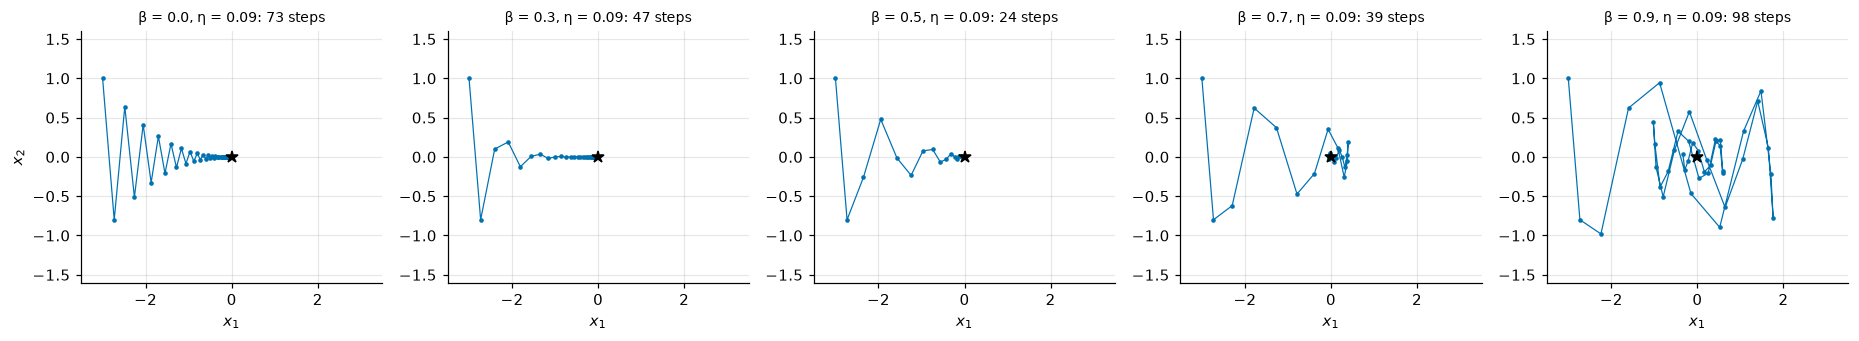

In [49]:
betas = [0.0, 0.3, 0.5, 0.7, 0.9]
eta = 0.09

fig, axes = plt.subplots(1, len(betas), figsize=(3.4 * len(betas), 3.2), squeeze=False)
for ax, beta in zip(axes[0], betas):
    path, reached = heavy_ball((1.0, 20.0), eta, beta, steps=2000)
    rates = [heavy_ball_rate(lam, eta, beta) for lam in (1.0, 20.0)]
    print(f"β = {beta:.2f}: steps = {reached}, rates (λ=1, λ=20) = ({rates[0]:.3f}, {rates[1]:.3f}), "
          f"√β = {math.sqrt(beta):.3f}")
    ax.plot(path[:41, 0], path[:41, 1], "o-", ms=2, lw=0.8, color=COLORS[0])
    ax.plot([0], [0], "k*", ms=8)
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-1.6, 1.6)
    ax.set_xlabel("$x_1$")
    ax.set_title(f"β = {beta}, η = {eta}: {reached} steps", fontsize=9)
axes[0][0].set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

*Your answer:*

> **Worked solution.**
>
> **With $\eta = 0.09$:** 73 steps for $\beta = 0$, 47 for 0.3, 24 for 0.5, 39 for 0.7 and 98 for 0.9. The best value is in the middle; too much momentum is *slower* than none. The paths show why: at $\beta = 0.9$ the iterate overshoots far past the minimum along $x_1$ and spirals in slowly, like an undamped ball rolling back and forth.
>
> **Explanation.** For each direction the iteration matrix has determinant $\beta$, so its two eigenvalues multiply to $\beta$. At $\beta = 0$ the rates are $|1 - \eta\lambda| = 0.91$ (flat) and $0.80$ (steep): the flat direction is the bottleneck. As $\beta$ grows, the flat direction's rate falls (the velocity accumulates the consistent gradient) until the eigenvalues become complex, when $(1 + \beta - \eta\lambda)^2 < 4\beta$. From then on both directions have rate exactly $\sqrt\beta$ ($0.707$ at $\beta = 0.5$, $0.949$ at $0.9$), which *increases* with $\beta$: once both modes oscillate, more momentum only means less damping. The best $\beta$ is near the point where both directions just become complex; here that is close to $0.5$ (the printed rates are $0.707$ for both). Theory for the optimal pair (Section 2) gives $\beta^* \approx 0.40$ with $\eta^* \approx 0.134$, close to our grid's winner.
>
> **Changing $\eta$.** With $\eta = 0.03$ plain GD needs 226 steps; more momentum is needed before the flat direction's eigenvalues become complex, and the best $\beta$ on a 0.1-spaced grid moves up to 0.7 (39 steps). With $\eta = 0.15$, plain GD diverges ($0.15 > 2/20$). Momentum's stability condition is $\eta\lambda < 2(1 + \beta)$ (the eigenvalue $-1$ is reached when $1 + \beta - \eta\lambda = -(1 + \beta)$), here $3 < 2(1 + \beta)$, i.e. $\beta > 0.5$: every $\beta \le 0.4$ diverges, $\beta = 0.5$ sits exactly on the boundary and never converges, and $\beta = 0.6$ is the fastest (28 steps). $\eta$ and $\beta$ interact: in practice, when increasing $\beta$, decrease $\eta$ to keep the effective rate $\eta/(1-\beta)$ similar.

### Exercise 2 (implement): the full `torch.optim.SGD`

Write `sgd_step(params, state, lr, momentum=0.0, dampening=0.0, nesterov=False, weight_decay=0.0)` that reproduces `torch.optim.SGD` with all these options. PyTorch's documented algorithm, for each parameter with gradient $\mathbf g_t$:

1. If `weight_decay` $\ne 0$: $\mathbf g_t \leftarrow \mathbf g_t + \lambda\boldsymbol\theta_{t-1}$.
2. If `momentum` $\mu \ne 0$: $\mathbf b_t = \mathbf g_t$ at the first step, otherwise $\mathbf b_t = \mu\mathbf b_{t-1} + (1 - \text{dampening})\,\mathbf g_t$. Then, if `nesterov`, $\mathbf g_t \leftarrow \mathbf g_t + \mu\mathbf b_t$; otherwise $\mathbf g_t \leftarrow \mathbf b_t$.
3. $\boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \text{lr}\cdot\mathbf g_t$.

Use `p.grad` for the gradient, do not modify `p.grad` itself, and keep the momentum buffers in `state`. The check compares with `torch.optim.SGD` over 50 steps for five configurations (with a tolerance of $10^{-5}$, so you do not need PyTorch's exact operation order).

<details>
<summary><b>💡 Hint</b></summary>

Note the special first step: the buffer is initialized to the gradient itself, *not* $(1 - \text{dampening})\,\mathbf g$, so starting from a zero buffer gives the wrong answer when dampening is nonzero. Use `state.get(i)` to tell whether a buffer exists yet, and `g = p.grad + weight_decay * p` (a new tensor) so that `p.grad` is not modified.

</details>

In [50]:
def sgd_step(params, state, lr, momentum=0.0, dampening=0.0, nesterov=False, weight_decay=0.0):
    with torch.no_grad():
        for i, p in enumerate(params):
            g = p.grad
            if weight_decay != 0:
                g = g + weight_decay * p
            if momentum != 0:
                buf = state.get(i)
                if buf is None:
                    buf = g.clone()
                    state[i] = buf
                else:
                    buf.mul_(momentum).add_(g, alpha=1 - dampening)
                g = g + momentum * buf if nesterov else buf
            p.add_(g, alpha=-lr)

In [51]:
for _cfg in [dict(), dict(momentum=0.9), dict(momentum=0.9, dampening=0.5), dict(momentum=0.9, nesterov=True),
             dict(momentum=0.8, weight_decay=0.05)]:
    _d = lockstep(lambda ps: torch.optim.SGD(ps, lr=0.05, **_cfg), lambda ps, st: sgd_step(ps, st, lr=0.05, **_cfg), steps=50)
    check(max(_d) < 1e-5, f"sgd_step with {_cfg} differs from torch.optim.SGD by up to {max(_d):.2e}")
# Deterministic edge cases on a 0-d parameter: the undamped first step, zero gradients, and p.grad left untouched.
_p = torch.tensor(1.0, requires_grad=True)
_st = {}
_p.grad = torch.tensor(1.0)
sgd_step([_p], _st, lr=0.1, momentum=0.9, dampening=0.5)          # buffer = g = 1 (no dampening at step 1)
check_close(_p.item(), 0.9, "parameter after the first step with dampening=0.5 (the first buffer is g itself)")
sgd_step([_p], _st, lr=0.1, momentum=0.9, dampening=0.5)          # buffer = 0.9·1 + 0.5·1 = 1.4
check_close(_p.item(), 0.9 - 0.14, "parameter after the second step with dampening=0.5")
check(_p.grad.item() == 1.0, "sgd_step must not modify p.grad")
_q = torch.tensor(2.0, requires_grad=True)
_q.grad = torch.tensor(0.0)
sgd_step([_q], {}, lr=0.1, weight_decay=0.5)                       # zero gradient: only the decay acts
check_close(_q.item(), 2.0 - 0.1 * 0.5 * 2.0, "zero gradient with weight_decay=0.5")
check(_q.grad.item() == 0.0, "sgd_step must not modify p.grad (weight decay must not be added in place)")
passed("Exercise 2")

✅ Exercise 2 passed


### Exercise 3 (debug): an Adam that almost works

The function below was meant to reproduce `torch.optim.Adam`. It trains — the loss goes down — but it does not match PyTorch. The buggy version is in the comments; it contains **two** bugs. Find them and write the corrected function body. The check, `check_adam_like_torch` (defined in the next cell), compares with `torch.optim.Adam` over 100 MLP steps and on two deterministic edge cases: a tensor whose gradient is exactly zero (it must not move) and one whose gradient is tiny ($10^{-6}$, where the first step should still be almost exactly $\eta$).

In [52]:
def check_adam_like_torch(step_fn):
    """Compare step_fn(params, state, lr=...) with torch.optim.Adam; raises AssertionError on a mismatch."""
    d = lockstep(lambda ps: torch.optim.Adam(ps, lr=1e-2), lambda ps, st: step_fn(ps, st, lr=1e-2), steps=100)
    check(max(d[:5]) < 1e-6, f"after 5 steps the Adam step differs from torch.optim.Adam by {max(d[:5]):.2e}")
    check(max(d) < 1e-4, f"after 100 steps the Adam step differs from torch.optim.Adam by {max(d):.2e}")
    # Edge cases: two parameter tensors with gradients 0 and 1e-6, for 3 steps.
    mine = [torch.zeros(2, dtype=f64, requires_grad=True), torch.zeros(3, dtype=f64, requires_grad=True)]
    ref = [p.detach().clone().requires_grad_(True) for p in mine]
    opt, state = torch.optim.Adam(ref, lr=1e-2), {}
    for _ in range(3):
        for group in (mine, ref):
            group[0].grad = torch.zeros(2, dtype=f64)
            group[1].grad = torch.full((3,), 1e-6, dtype=f64)
        step_fn(mine, state, lr=1e-2)
        opt.step()
        check(torch.equal(mine[0], torch.zeros(2, dtype=f64)), "a parameter with zero gradient must not move")
        check_close(mine[1], ref[1], "parameter with gradient 1e-6 (edge case)", rtol=1e-9, atol=1e-12)
    check_close(ref[1][0].item(), -3e-2 * 1e-6 / (1e-6 + 1e-8), "torch reference after 3 steps", rtol=1e-6)

<details>
<summary><b>💡 Hint</b></summary>

Compare line by line with the equations of Section 4. How many times is the step counter incremented per call, if the model has 6 parameter tensors? And where exactly does $\varepsilon$ go — inside or outside the square root?

</details>

In [53]:
def my_adam_step(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    # Buggy version:
    #     if not state:
    #         state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    #     with torch.no_grad():
    #         for p, m, v in zip(params, state["m"], state["v"]):
    #             state["t"] += 1
    #             t = state["t"]
    #             g = p.grad
    #             m.lerp_(g, 1 - beta1)
    #             v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
    #             denom = (v / (1 - beta2**t) + eps).sqrt()
    #             p.addcdiv_(m, denom, value=-lr / (1 - beta1**t))
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    state["t"] += 1                       # once per optimizer step, not once per parameter tensor
    t = state["t"]
    with torch.no_grad():
        for p, m, v in zip(params, state["m"], state["v"]):
            g = p.grad
            m.lerp_(g, 1 - beta1)
            v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
            denom = (v.sqrt() / (1 - beta2**t) ** 0.5).add_(eps)     # eps outside the square root
            p.addcdiv_(m, denom, value=-lr / (1 - beta1**t))

In [54]:
check_adam_like_torch(my_adam_step)
passed("Exercise 3")

✅ Exercise 3 passed


The original buggy code fails this same check, and so does each bug on its own (the other one fixed). The cell below runs the check on all three versions and prints how they differ from `torch.optim.Adam`:

In [55]:
def adam_buggy_original(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """The buggy version from the exercise, verbatim."""
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    with torch.no_grad():
        for p, m, v in zip(params, state["m"], state["v"]):
            state["t"] += 1
            t = state["t"]
            g = p.grad
            m.lerp_(g, 1 - beta1)
            v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
            denom = (v / (1 - beta2**t) + eps).sqrt()
            p.addcdiv_(m, denom, value=-lr / (1 - beta1**t))


def adam_bug_counter(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """Only the step-counter bug."""
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    with torch.no_grad():
        for p, m, v in zip(params, state["m"], state["v"]):
            state["t"] += 1
            t = state["t"]
            g = p.grad
            m.lerp_(g, 1 - beta1)
            v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
            denom = (v.sqrt() / (1 - beta2**t) ** 0.5).add_(eps)
            p.addcdiv_(m, denom, value=-lr / (1 - beta1**t))


def adam_bug_eps(params, state, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """Only the eps-inside-the-square-root bug."""
    if not state:
        state.update(t=0, m=[torch.zeros_like(p) for p in params], v=[torch.zeros_like(p) for p in params])
    state["t"] += 1
    t = state["t"]
    with torch.no_grad():
        for p, m, v in zip(params, state["m"], state["v"]):
            g = p.grad
            m.lerp_(g, 1 - beta1)
            v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
            denom = (v / (1 - beta2**t) + eps).sqrt()
            p.addcdiv_(m, denom, value=-lr / (1 - beta1**t))


for name, fn in [("original (both bugs)", adam_buggy_original), ("counter bug only", adam_bug_counter),
                 ("eps bug only", adam_bug_eps)]:
    _d = lockstep(lambda ps: torch.optim.Adam(ps, lr=1e-2), lambda ps, st, f=fn: f(ps, st, lr=1e-2), steps=100)
    print(f"{name:20s}: max |difference| after 1, 5, 100 steps = {_d[0]:.1e}, {_d[4]:.1e}, {_d[99]:.1e}")
    try:
        check_adam_like_torch(fn)
        print(f"{'':20s}  check passed (unexpected!)")
    except AssertionError as err:
        print(f"{'':20s}  check fails as it should: {err}")

original (both bugs): max |difference| after 1, 5, 100 steps = 9.9e-03, 4.6e-02, 1.3e+00


                      check fails as it should: after 5 steps the Adam step differs from torch.optim.Adam by 4.60e-02


counter bug only    : max |difference| after 1, 5, 100 steps = 4.8e-03, 5.2e-02, 1.1e+00


                      check fails as it should: after 5 steps the Adam step differs from torch.optim.Adam by 5.23e-02


eps bug only        : max |difference| after 1, 5, 100 steps = 9.8e-03, 4.1e-02, 7.1e-01


                      check fails as it should: after 5 steps the Adam step differs from torch.optim.Adam by 4.14e-02


> **Worked solution.**
>
> **Bug 1: the step counter is incremented inside the parameter loop.** Our MLP has 6 parameter tensors (three weights, three biases), so in the first call the tensors see $t = 1, 2, \dots, 6$, and after $k$ calls the last tensor uses $t = 6k$. The bias corrections $1 - \beta^t$ are then wrong for every tensor except the first, and they decay toward 1 six times too fast — so the early steps have the wrong size. At the very first call, the sixth tensor uses $t = 6$: $\hat m = 0.1g/(1 - 0.9^6) \approx 0.21g$ and $\sqrt{\hat v} = \sqrt{0.001g^2/(1 - 0.999^6)} \approx 0.41|g|$, a step of about $0.52\eta$ instead of $\eta$. The difference is visible after the first step. The counter counts optimizer steps, so it belongs outside the loop: one increment per call.
>
> **Bug 2: $\varepsilon$ inside the square root.** $\sqrt{\hat v + \varepsilon}$ instead of $\sqrt{\hat v} + \varepsilon$. With $\varepsilon = 10^{-8}$, the first form puts a floor of $\sqrt{\varepsilon} = 10^{-4}$ under the denominator, which changes the update of every parameter whose gradients are of order $10^{-4}$ or smaller — and there are always some. At the first step $\hat v = g^2$, so every parameter with $|g| \lesssim 10^{-4}$ takes a step smaller than $\eta$ instead of $\approx\eta$; the printed differences show this bug alone already changes the first step by about $10^{-2}$, and the gap keeps growing over training (Section 4). Some libraries define their Adam variant with $\varepsilon$ inside; it is a legitimate *different* algorithm, but not PyTorch's.
>
> Both bugs leave a working-looking optimizer: the loss goes down and nothing crashes. Only a comparison with a trusted reference reveals them.

### Exercise 4 (investigate): batch size and learning rate

When the batch size changes, should the learning rate change too? A widely used heuristic, the **linear scaling rule** (Goyal et al. 2017, "Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour"), says: when multiplying the batch size by $k$, multiply the SGD learning rate by $k$. **Its assumption:** one step on a batch of $kB$ examples with rate $k\eta$ should do about what $k$ consecutive steps on batches of $B$ with rate $\eta$ do — true if the gradient barely changes over those $k$ small steps, so that their sum is close to $k$ times one large-batch gradient. That fails when the larger rate approaches the curvature limit of notebook 03 ($k\eta$ cannot exceed $2/\lambda_{\max}$ however large $B$ is) and early in training when the gradient changes quickly; Goyal et al. used warmup for the latter and report that the rule broke down beyond a certain batch size.

The scaffold trains the spiral MLP with plain SGD for a fixed budget of **10 epochs**, for batch sizes $B \in \{8, 32, 128, 512\}$, sweeping the learning rate over a grid of powers of 2 (two seeds each), and stores the mean final training loss in `table[B]` (one value per learning rate in `lr_grid`). Run it (about 15 seconds). Then, in the following cell, write the analysis: a dictionary `best_lr_ex` mapping each batch size to the grid learning rate with the lowest loss, and a figure with two panels — final loss against learning rate (log $x$-axis, one curve per $B$), and best learning rate against $B$ on log–log axes together with the linear-scaling prediction from $B = 8$. Answer:

1. How does the best learning rate change with $B$? Compare with the linear scaling rule (the dashed line).
2. How does the best achievable loss change with $B$, for this fixed number of epochs? Why?
3. What do your results suggest about using larger batches to train faster?

<details>
<summary><b>💡 Hint</b></summary>

With a fixed number of epochs, a batch size $k$ times larger means $k$ times fewer steps. Linear scaling tries to compensate by making each step $k$ times larger — which works only while the larger lr stays below the stability limit set by the curvature (Section 2 of notebook 03).

</details>

In [56]:
batch_sizes_ex = [8, 32, 128, 512]
lr_grid = [0.02 * 2**k for k in range(9)]          # 0.02 ... 5.12
ex_seeds = [0, 1]


def final_loss_sgd(lr, batch_size, seed, epochs=10):
    model = make_mlp(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        for idx in shuffled_batches(N, batch_size, gen):
            opt.zero_grad()
            F.cross_entropy(model(X_sp[idx]), y_sp[idx]).backward()
            opt.step()
    return full_loss(model)


t0 = time.perf_counter()
table = {}
for bs in batch_sizes_ex:
    table[bs] = [sum(final_loss_sgd(lr, bs, s) for s in ex_seeds) / len(ex_seeds) for lr in lr_grid]
print(f"{len(batch_sizes_ex) * len(lr_grid) * len(ex_seeds)} runs in {time.perf_counter() - t0:.1f} s")
for bs in batch_sizes_ex:
    print(f"B = {bs:>3}: losses over the grid = {[round(v, 2) for v in table[bs]]}")

72 runs in 17.5 s
B =   8: losses over the grid = [1.04, 1.0, 0.81, 0.53, 0.59, 0.95, 1.14, 1.17, 1.17]
B =  32: losses over the grid = [1.06, 1.05, 1.04, 1.0, 0.85, 0.79, 0.88, 1.13, 1.35]
B = 128: losses over the grid = [1.08, 1.07, 1.06, 1.05, 1.04, 1.02, 0.97, 1.09, 1.18]
B = 512: losses over the grid = [1.1, 1.09, 1.08, 1.07, 1.06, 1.06, 1.04, 1.04, 1.19]


<details>
<summary><b>💡 Hint</b></summary>

`min(range(len(lr_grid)), key=lambda i: table[bs][i])` is the index of the smallest loss. Cap diverged or very large losses (e.g. `min(v, 2.0)`) before plotting so one bad run does not squash the axis. The linear-scaling line is `best_lr_ex[8] * B / 8`.

</details>

B =   8: best lr = 0.16, best final loss = 0.531
B =  32: best lr = 0.64, best final loss = 0.793
B = 128: best lr = 1.28, best final loss = 0.972
B = 512: best lr = 2.56, best final loss = 1.040


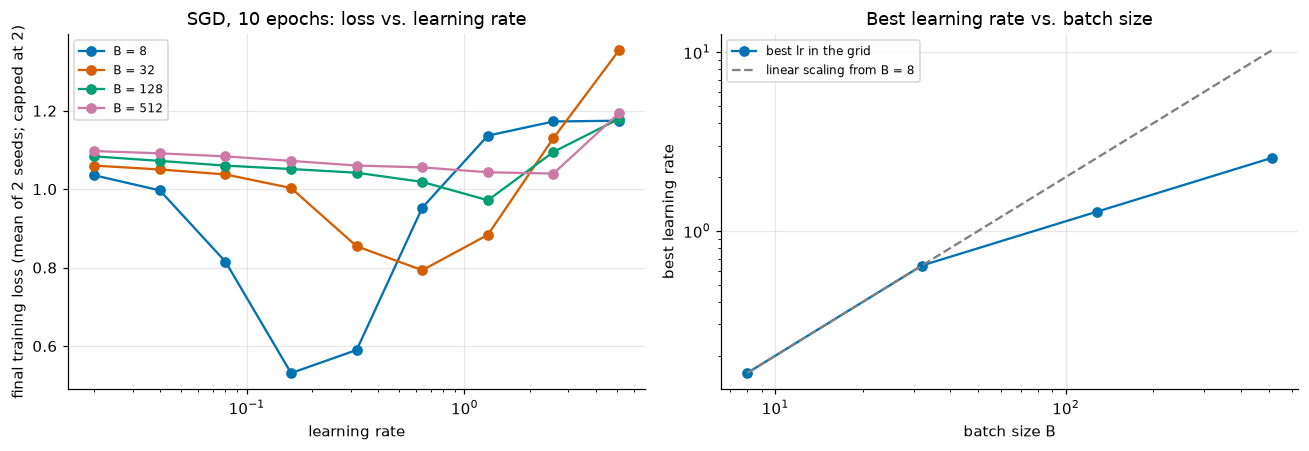

In [57]:
best_lr_ex = {bs: lr_grid[min(range(len(lr_grid)), key=lambda i: table[bs][i])] for bs in batch_sizes_ex}
for bs in batch_sizes_ex:
    print(f"B = {bs:>3}: best lr = {best_lr_ex[bs]:.2f}, best final loss = {min(table[bs]):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for k, bs in enumerate(batch_sizes_ex):
    ax1.semilogx(lr_grid, [min(v, 2.0) for v in table[bs]], "o-", color=COLORS[k], label=f"B = {bs}")
ax1.set_xlabel("learning rate")
ax1.set_ylabel("final training loss (mean of 2 seeds; capped at 2)")
ax1.set_title("SGD, 10 epochs: loss vs. learning rate")
ax1.legend(fontsize=8)
ax2.loglog(batch_sizes_ex, [best_lr_ex[bs] for bs in batch_sizes_ex], "o-", color=COLORS[0], label="best lr in the grid")
ax2.loglog(batch_sizes_ex, [best_lr_ex[8] * bs / 8 for bs in batch_sizes_ex], "--", color="gray",
           label="linear scaling from B = 8")
ax2.set_xlabel("batch size B")
ax2.set_ylabel("best learning rate")
ax2.set_title("Best learning rate vs. batch size")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [58]:
check(isinstance(best_lr_ex, dict) and sorted(best_lr_ex) == batch_sizes_ex, "best_lr_ex should have one entry per batch size")
for _bs in batch_sizes_ex:
    check(best_lr_ex[_bs] in lr_grid, f"best_lr_ex[{_bs}] should be a value from lr_grid")
    check_close(table[_bs][lr_grid.index(best_lr_ex[_bs])], min(table[_bs]), f"loss at best_lr_ex[{_bs}]")
passed("Exercise 4 analysis")

✅ Exercise 4 analysis passed


*Your conclusion:*

> **Worked solution.**
>
> **Best learning rate.** It grows with the batch size: 0.16 for $B = 8$, 0.64 for $B = 32$, 1.28 for $B = 128$ and 2.56 for $B = 512$ (on a grid with factor-2 resolution, so each value is uncertain by about a factor of 2). From 8 to 32 the growth is roughly linear (×4); beyond that it is about ×2 per ×4 in batch size — **sublinear**, below the dashed linear-scaling line, which would predict 10.24 at $B = 512$. Linear scaling describes the small-batch regime, where the noise dominates and a bigger batch lets each step be proportionally bigger; at larger batches the learning rate runs into the curvature limit of notebook 03 (the largest grid value, 5.12, is worse than smaller ones for every batch size), so it cannot keep growing. This is the counterexample to applying the rule blindly: from $B = 8$, it would prescribe 10.24 at $B = 512$, four times the best value and beyond the range where training works at all.
>
> **Best loss.** With the number of epochs fixed, the best loss gets *worse* as $B$ grows: about 0.53 at $B = 8$, 0.79 at $B = 32$, 0.97 at $B = 128$ and 1.04 at $B = 512$. Larger batches mean fewer steps (3750 steps for $B = 8$ against 60 for $B = 512$), and once the learning rate can no longer grow in proportion, fewer steps means less progress. Each large-batch step is a better gradient estimate, but on this task an estimate from 8 examples is already good enough to make progress (Section 1).
>
> **Implication.** Larger batches train faster per step and use hardware better (Chapter 5), but per example processed they are less efficient beyond some batch size, and scaling the learning rate only helps up to that point. Linear scaling is a useful starting point when changing $B$, to be confirmed with a small sweep (and, for large batches, typically combined with warmup, as Goyal et al. did). Our conclusion rests on two seeds, one task and one optimizer; a careful study would use more seeds and a finer grid (notebook 26).

## Summary and what's next

- **Mini-batch SGD.** A uniformly sampled mini-batch gradient is an **unbiased** estimate of the full gradient (each example is included with probability $B/N$); its expected squared error is $\frac{\sigma^2}{B}\cdot\frac{N-B}{N-1}$, verified numerically. Batches come from a fresh random permutation each epoch; an epoch is $\lceil N/B\rceil$ steps. Measured by examples processed, mini-batches beat full-batch GD by a wide margin because examples are redundant.
- **Momentum** accumulates gradients, $\mathbf v \leftarrow \beta\mathbf v + \mathbf g$: oscillating components cancel, consistent ones add up, with effective learning rate $\eta/(1-\beta)$ and memory $\sim 1/(1-\beta)$ steps. On a quadratic each direction converges at the spectral radius of a 2×2 matrix, $\sqrt\beta$ when its eigenvalues are complex; tuned, steps grow like $\sqrt\kappa$ instead of $\kappa$. Too much momentum is slower than none.
- **RMSProp** divides each coordinate's gradient by a running RMS, making steps unit-free and handling axis-aligned differences in scale; it cannot fix rotated ill-conditioning, and without bias correction its first step is $\eta/\sqrt{1-\alpha}$.
- **Adam** = momentum + RMSProp + bias correction; $\mathbb E[\mathbf m_t] = (1-\beta_1^t)\,\mathbb E[\mathbf g]$ explains the correction. Its steps are about $\eta$ in size and invariant to rescaling the loss, which is why it needs little tuning. We matched `torch.optim.SGD`, `RMSprop` and `Adam` bit for bit, and saw that rounding-level differences grow over training, so optimizer tests must be designed with care.
- **Weight decay.** For SGD an L2 penalty equals multiplying the weights by $1 - \eta\lambda$. In Adam the L2 gradient is rescaled per parameter, so `Adam(weight_decay)` and `AdamW(weight_decay)` are different regularizers; at the same $\lambda$ the first crippled our MLP while the second barely changed it.
- **Schedules**: step, cosine, warmup; call `scheduler.step()` after `optimizer.step()`. Warmup protects the noisy first steps of adaptive methods (intuition; Liu et al. 2020). The **range test** gives a quick starting learning rate.
- **Comparisons** of optimizers are only meaningful with each one's learning rate tuned; at their best learning rates, the gaps shrink, and learning rates that are good for one optimizer can be useless for another.

Throughout this chapter the networks have had at most a few hidden layers, and we have taken for granted that more layers mean more power. Notebook 20 looks inside trained networks — what each layer's features represent — and asks when depth actually helps, comparing deep and wide networks at matched parameter counts. Chapter 4 then turns the pieces of this chapter into a reliable training system, starting with `Dataset` and `DataLoader` (notebook 21), which replace our hand-written `shuffled_batches`.